# Visión por Computador - Práctica 2 - Procesado de Imágenes

#### 10 puntos   |   Fecha de entrega: 15 de Noviembre de 2026, 23:59   |   Forma de entrega: a través de la tarea creada en https://pradogrado2627.ugr.es/

### Estudiante: Ismael Sallami Moreno



---

## Normas de desarrollo y entrega de la práctica

1. Para este trabajo, al igual que para los demás, se debe presentar código, resultados, discusión de los mismos, y presentación y análisis del trabajo realizado, todo integrado en el propio Google Colab Notebook (es decir, no se entrega ninguna memoria separada en `.pdf` ni ningún código `.py`). Se recuerda que código y resultados sin informe explicativo no puntúa. Resulta también fundamental recordar que solo se acepta la entrega de ficheros `.ipynb` (no resulta válido entregar un fichero `.py`).

2. En relación con el punto anterior, se recuerda que se proporciona un Notebook, denominado `Ejemplo_Otsu.ipynb`, que muestra un ejemplo de respuesta y solución a un potencial ejercicio. El propósito de este Notebook es servir de referencia al alumnado acerca de cómo responder los ejercicios planteados. Véase que, por ejemplo, en aras de diferenciar con facilidad enunciados y respuestas, estas últimas se presentan en otro color (azul, en ese caso).

3. El diseño de celdas del documento debe ser respetado. Es decir, no se puede modificar el orden de los ejercicios o alterar la estructura del Notebook, de forma que dificulte localizar los contenidos. Aunque sí se puede, por ejemplo, crear nuevas subsecciones dentro de las secciones ya existentes para estructurar y organizar con más claridad las respuestas, así como para incluir los experimentos extra que se deseen.

4. Tal y como se muestra en `Ejemplo_Otsu.ipynb`, no hay ningún problema en emplear técnicas de IA generativa (como ChatGPT o Gemini) para crear el código de los distintos ejercicios o para enriquecer el análisis y descripción del trabajo realizado (aunque, obvia decirlo, su uso no es obligatorio). Pero, en caso de usarse, sí se debe aclarar de qué modo se ha usado la IA, con qué objetivo, y se debe demostrar que se entiende perfectamente lo que se ha hecho.

5. Solo se entregará el fichero `.ipynb` (incorporando código, resultados, y explicación del trabajo realizado y los resultados obtenidos) y no se enviarán las imágenes empleadas. El path para la lectura de imágenes, o cualquier otro fichero de entrada, debe ser siempre “/content/drive/My Drive/images/nombre_fichero”.

6. El código deberá  presentarse adecuadamente comentado y con los resultados obtenidos en cada apartado, junto con la presentación del trabajo realizado y la discusión y análisis de los resultados obtenidos. Es importante reiterar que la entrega de código sin informe explicativo o valoraciones no puntúa. Por otro lado, el código debe ir comentado en comentarios en celdas de código, mientras que el análisis y discusión, tanto del trabajo realizado como de los resultados obtenidos, debe ir en celdas de texto.

Este trabajo de implementación tiene como objetivo principal **familiarizarse con el uso de filtros de convolución, así como del cálculo de las derivadas de una imagen y sus posibles aplicaciones**.




### Materiales de Apoyo

En caso de que el alumnado tenga dudas sobre Python, OpenCV o el uso de Google Colab, se recuerda que en PRADO hay materiales de apoyo (https://pradogrado2627.ugr.es/mod/folder/view.php?id=83733):
-  Introducción a Python: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/1.%20Introduccion%20a%20Python.pdf
- Introducción a NumPy, Matplotlib y Scikit-learn: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/2.%20Introducci%C3%B3n%20a%20Numpy%20Matplotlib%20y%20sklearn.pdf
- Notebook con toda la información anterior (y más cosas): https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Guia_Python.ipynb
- Ejercicios y ejemplos de repaso: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/3.%20Ejercicios%20y%20ejemplos%20de%20repaso.pdf
- Fundamentos de Python para lectura, visualización y manipulación de imágenes: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/4.%20Fundamentos%20de%20Python%20para%20manipulacion%20de%20imagenes.pdf(y Notebook asociado: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Guia_fundamentos_imagenes.ipynb)
- Ideas sobre cómo redactar un documento académico-científico (útil para saber cómo documentar las respuestas a los ejercicios, el Notebook en su conjunto, y la memoria del proyecto final o de un TFG/TFM): https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Algunas%20ideas%20sobre%20c%C3%B3mo%20elaborar%20un%20informe%20acad%C3%A9mico-cient%C3%ADfico.pdf
- Ejemplo de respuesta a un hipotético ejercicio sobre el algoritmo de umbralización de Otsu: https://pradogrado2627.ugr.es/pluginfile.php/153448/mod_folder/content/0/Ejemplo_Otsu.ipynb



---



## Organización y uso de IA

Cada apartado sigue el orden **teoría → código → análisis**. Toda cifra indica de dónde sale:

- `2.1`, `2.2`, `2.3`: diapositivas de teoría (*ImageFiltering*, *GaussianFilters_Edges*, *Pyramids*); `Assignment2`: diapositivas del enunciado; "d." = número de diapositiva.
- *salida*: valor impreso por la celda de código anterior.
- *cálculo propio*: cuenta hecha a partir de la fórmula que se indica.

**Uso de IA generativa (norma 4).** Se ha usado Claude (Anthropic) como apoyo para repasar la teoría, proponer código y redactar borradores. Todo se ha revisado, ejecutado y comprobado frente a OpenCV y frente a casos sintéticos de resultado conocido.

Las imágenes se leen de `/content/drive/My Drive/images/`, salvo el par en color del Ejercicio 3, que se descarga de una URL. No se escribe nada en disco.

## Funciones de apoyo y conexión con Google Drive

In [ ]:
# We start by getting access to the drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

In [ ]:
# We import the main potential modules to use
import os,sys
import cv2, numpy as np, math
from matplotlib import pyplot as plt
# change directory
%cd '/content/drive/My Drive'
#  the current directory
%pwd

# This allows to display images  and to save  them in cells
%matplotlib inline
# this definition allows to read files in a specific path
get_image = lambda route: os.path.join('/content/drive/My Drive/images', route)

Las funciones que se incluyen a continuación, se proporcionan como ayuda/apoyo para el estudiante. **En caso de que el alumnado prefiera utilizar otras funciones para lectura, normalización y visualización de imágenes, tiene total libertad para hacerlo, pero sí debe justificar y explicar razonadamente el motivo de dicho cambio y describir las modificaciones realizadas.**

Recuérdese que todas las imágenes a emplear durante las prácticas de todo el curso se pueden encontrar en el enlace de Google Drive indicado en PRADO: https://pradogrado2627.ugr.es/mod/url/view.php?id=83732 En concreto, https://drive.google.com/drive/folders/1UtvY8q6w1Cz9a9T9zxIqSweoRLgNwoW-

In [3]:
'''
This function receives a string with the filename of the image to read,
and a flag indicating if we want to read it in color/RGB (flagColor=1) or gray level (flagColor=0)

Example of use:
im1=readIm(get_image('apple.jpg'),0)

'''
def readIm(filename, flagColor=1):
  # cv2 reads BGR format
  im=cv2.imread(filename)
  # change to  RGB and return the image
  if(flagColor):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
  # change from BGR to grayscale instead if flag is 0
  return cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

In [4]:
'''
This function receives an array of arbitrary real numbers (that could include even negative values),
and returns an 'image' in the range [0,1].
flag_GLOBAL allows the user to normalize the whole image (including all channels) or to normalize
each channel/band independently.
'''
def rangeDisplay01(im, flag_GLOBAL=True):
    im = im.astype(float)
    min_val = im.min()
    max_val = im.max()
    if max_val == min_val:
        return np.zeros_like(im)
    if flag_GLOBAL or im.ndim == 2:
        im = (im - min_val) / (max_val - min_val)
    else:
        # Band-wise normalization
        for band in range(im.shape[2]):
            min_val = im[:, :, band].min()
            max_val = im[:, :, band].max()
            if max_val == min_val:
                im[:, :, band] = 0
            else:
                im[:, :, band] = (im[:, :, band] - min_val) / (max_val - min_val)
        # Note: remember that, for plt.imshow with RGB data,
        # the valid range is [0..1] for floats and [0..255] for integers.
    return im

In [5]:
'''
This function displays a single image, including a title, using a magnification factor.

Example of use:
im1=readIm(get_image('apple.jpg'),0)
displayIm(im1,'Manzana',0.5)

'''
def displayIm(im, title='Result',factor= 2):
  # First normalize range
  max=np.max(im)
  min=np.min(im)
  if min<0 or max>255:
    im=rangeDisplay01(im,flag_GLOBAL=True)
  if len(im.shape) == 3:
    # im es tribanda
    plt.imshow(im, cmap='jet')
  else:
    # im es monobanda
    plt.imshow(im, cmap='gray')
  figure_size = plt.gcf().get_size_inches()
  plt.gcf().set_size_inches(factor * figure_size)
  plt.title(title)
  plt.xticks([]), plt.yticks([]) # eliminamos numeración
  plt.show()

In [6]:
'''
This function displays multiple images (including a title and using a magnification factor)
of equal size. The input to the function is a list of images.

Example of use:
im1=readIm(get_image('apple.jpg'),1)
images = [im1,im1,im1]

displayMI_ES(images, title='Manzanas',factor=1)

IMPORTANT NOTE: it is important to notice that this function stacks all images
and later call displayIm(). This implies that the normalization (rangeDisplay01()) is done
at the very end of the process. As a consequence, if the stacked images have different
range values they can be displayed in a "weird" way (with black regions (pixel value = 0)
looking grey). In case the visualization seems to be a problem, a possible solution
would be to create vim using vim.append(rangeDisplay01(...)). In this way, all images
would be on the same range of values (negative values around 0 (black),
0 values around 0.5 (grey), and positive values closer to 1 (white))

'''
def displayMI_ES(vim, title='Result',factor=2):
  # We set the maximun number of images to concatenate by columns
  maxcolumns=3
  # number of images to display
  numberim=len(vim)
  # The simplest case, one row: the maximum number of columns is larger than the images to stack
  # This is, by default, we put together the images column-wise
  if len(vim) < maxcolumns:
    out=vim[0]
    for item in range(1,len(vim)):
      #displayIm(out,str(item),1)
      out=np.hstack((out,vim[item]))

  # Else, if maxcolumns is smaller or equal than the number of images to stack
  else:
    # We check if all rows and columns are going to be 'busy', or if otherwise we need an extra-row
    if np.mod(len(vim),maxcolumns)== 0:
      maxrows=numberim//maxcolumns
    else:
      maxrows=numberim//maxcolumns+1

    # we build up the first block-row
    out=vim[0]
    for item in range(1,maxcolumns):
      out=np.hstack((out,vim[item]))
    # We build up the rest of block-rows
    for block in range(1,maxrows):
      #print(block)
      row=vim[block*maxcolumns]
      for item in range(1,maxcolumns):
        # We still have images to stack
        if block*maxcolumns+item < numberim:
          row=np.hstack((row,vim[block*maxcolumns+item]))
        # We do not have more images, and we have to fill with black
        else:
          row=np.hstack((row,np.zeros(vim[0].shape,dtype=vim[0].dtype)))
          #print(row.dtype)
          # if we don't include ',dtype=vim[0].dtype', np.zeros will include float
          # numbers in the matrix. This will make that the whole matrix will be
          # considered as floats, and values larger than 1 will be clipped to 1,
          # displaying an almost totally white image
      # add the new block-row
      out=np.vstack((out,row))
  return displayIm(out,title,factor)

In [7]:
# EL ALUMNADO DEBE COPIAR AQUÍ SUS FUNCIONES DE DISCRETIZACIÓN DE KERNELS GAUSSIANOS
# (desarrolladas en último apartado de la Práctica 1):
# GaussFunc, GaussDeriv1Func, GaussDeriv2Func y gaussianMask1D

"""
    Evalúa la función Gaussiana 1D de media cero para una posición x
    y una desviación estándar sigma.
"""
def GaussFunc(x,sigma):
    # Sin la constante 1/(sigma*sqrt(2*pi)): la forma no cambia y la máscara
    # se normaliza después dividiendo por la suma de sus muestras
    return np.exp(-x**2 / (2.0 * sigma**2))  # e^(-x^2 / (2*sigma^2))

"""
    Evalúa la primera derivada de la función Gaussiana 1D de media cero
    para una posición x y una desviación estándar sigma.
"""
def GaussDeriv1Func(x,sigma):
    # g'(x) = -(x / sigma^2) * g(x)
    return -(x / sigma**2) * GaussFunc(x, sigma)  # regla de la cadena

"""
    Evalúa la segunda derivada de la función Gaussiana 1D de media cero
    para una posición x y una desviación estándar sigma.
"""
def GaussDeriv2Func(x,sigma):
    # g''(x) = ((x^2 - sigma^2) / sigma^4) * g(x)
    return ((x**2 - sigma**2) / sigma**4) * GaussFunc(x, sigma)  # derivada del producto -(x/sigma^2)*g(x)

"""
    Construye un kernel Gaussiano 1D discreto, o una de sus derivadas,
    a partir de sigma o del tamaño deseado para la máscara.

    El parámetro order determina el tipo de kernel:
        order = 0 -> Gaussiana
        order = 1 -> primera derivada de la Gaussiana
        order = 2 -> segunda derivada de la Gaussiana

    Debe proporcionarse sigma o sizeMask, pero no ambos simultáneamente.
    Si solamente se proporciona sigma, debe determinarse un tamaño
    apropiado para el kernel. Si solamente se proporciona sizeMask,
    debe obtenerse un valor apropiado de sigma.

    El kernel debe construirse discretizando la función correspondiente
    en las posiciones espaciales que forman la máscara y debe aplicarse
    la normalización apropiada según el orden de la derivada.
"""
def gaussianMask1D(sigma=0, sizeMask=0, order=0):
    if sigma > 0 and sizeMask == 0:  # caso 1: nos dan sigma
        # Dado sigma: menor entero k que cumple k >= 3*sigma, y T = 2k + 1
        k = int(np.ceil(3.0 * sigma))  # k = techo de 3*sigma
        sizeMask = 2 * k + 1  # tamaño impar de la máscara
    elif sizeMask > 0 and sigma == 0:  # caso 2: nos dan el tamaño
        # Dado T (impar): k = (T - 1) / 2 = 3*sigma  ->  sigma = (T - 1) / 6
        if sizeMask % 2 == 0:  # el tamaño tiene que ser impar
            raise ValueError('El tamaño de la máscara debe ser impar.')  # error si es par
        k = (sizeMask - 1) // 2  # radio de la máscara
        sigma = k / 3.0  # sigma = (T - 1) / 6
    else:  # se han dado los dos parámetros o ninguno
        raise ValueError('Debe proporcionarse exactamente uno de los dos parámetros: sigma o sizeMask.')  # error de uso

    # Posiciones enteras centradas en 0: -k, ..., 0, ..., k
    x = np.arange(-k, k + 1)  # vector de posiciones de la máscara

    # Suma de las muestras de la Gaussiana: versión discreta de sigma*sqrt(2*pi).
    # Se usa como constante de normalización común para los tres órdenes
    norm = np.sum(GaussFunc(x, sigma))  # constante de normalización

    if order == 0:  # Gaussiana
        mask = GaussFunc(x, sigma) / norm                    # suma exactamente 1
    elif order == 1:  # primera derivada
        mask = sigma * GaussDeriv1Func(x, sigma) / norm      # escala normalizada (sigma^1)
    elif order == 2:  # segunda derivada
        mask = sigma**2 * GaussDeriv2Func(x, sigma) / norm   # escala normalizada (sigma^2)
    else:  # orden no válido
        raise ValueError('El parámetro order debe ser 0, 1 o 2.')  # error si order no es 0, 1 o 2

    return mask

Funciones copiadas sin cambios de la Práctica 1. Dos detalles que se usan en toda la práctica:

- **Tamaño:** dado $\sigma$, $T=2\lceil3\sigma\rceil+1$; dado $T$, $\sigma=(T-1)/6$ (`2.2`, d. 11).
- **Normalización de escala:** las máscaras de 1.ª y 2.ª derivada ya salen multiplicadas por $\sigma$ y $\sigma^2$ (`2.2`, d. 66 y 68). Por eso la LoG del 1B no se vuelve a multiplicar por $\sigma^2$.

# <font color='blue'>**Ejercicio 1: Filtrado Gaussiano** (3 puntos)

<font color='blue'>En este ejercicio aprenderemos a aplicar las máscaras de convolución ya discretizadas en la práctica 1 (https://pradogrado2627.ugr.es/mod/folder/view.php?id=83734). También buscamos hacerlo de un modo eficiente, y es por ello que, en toda la práctica (y no solo en este ejercicio), se exige el uso de convoluciones 1D (separables).





## <font color='blue'>A) (1 punto)

<font color='blue'>En este apartado se debe leer una imagen en escala de grises (`'cat.bmp'`) y esta debe ser filtrada mostrando el resultado de la convolución con: a) una Gaussiana, b) la primera derivada de la Gaussiana en $X$, c) la primera derivada de la Gaussiana en $Y$, d) la segunda derivada de la Gaussiana en $X$, y e) la segunda derivada de la Gaussiana en $Y$. Para ello, hay que:
1. emplear los siguientes sigmas ($\{1, 2, 4, 8, 16\}$);
2. usar la función de OpenCV `sepFilter2D()` con las máscaras 1D calculadas a partir de las funciones desarrolladas en la práctica anterior;
3. mostrar todas las imágenes dentro del mismo canvas (para facilitar su comparación);
4. y analizar los resultados obtenidos y discutir si se corresponden con lo que se esperaría obtener en base a nuestro conocimiento de la teoría. En este sentido, por ejemplo, resulta clave explicar qué par de kernels se aplican en cada caso, en qué orden y por qué.




### Teoría (1A)

- **Separabilidad.** $G(x,y)=g(x)\,g(y)$, y lo mismo sus derivadas: $\dfrac{\partial^{m+n}G}{\partial x^m\partial y^n}=g^{(m)}(x)\,g^{(n)}(y)$, es decir, se deriva en una dirección y se suaviza en la otra (`2.2`, d. 15-20 y 58). Basta un kernel 1D por filas (`kernelX`) y otro por columnas (`kernelY`): $2T$ multiplicaciones por píxel en lugar de $T^2$ (`2.2`, d. 19).
- **Convolución frente a correlación.** `sepFilter2D` calcula una correlación (`2.1`, d. 70). Con $g$ y $g''$, que son simétricas, da igual; con $g'$, antisimétrica, el signo saldría cambiado. Por eso se voltean las máscaras (`[::-1]`) y se comprueba con un escalón sintético.
- **`ddepth = cv2.CV_64F`**, para que los valores negativos de las derivadas no se saturen a 0 (`Assignment2`, d. 11).

**Qué se espera:** más emborronamiento al subir $\sigma$; $\partial/\partial x$ resalta los bordes verticales y $\partial/\partial y$ los horizontales; la 2.ª derivada da una doble respuesta $\pm$ con el paso por cero en el borde (`2.2`, d. 48); con $\sigma$ grande solo sobreviven las estructuras grandes (`2.2`, d. 70).

Escalón: dI/dx = 99.22 | dI/dy = 0.0
Tamaño T de la máscara para sigma = [1, 2, 4, 8, 16] -> [7, 13, 25, 49, 97]


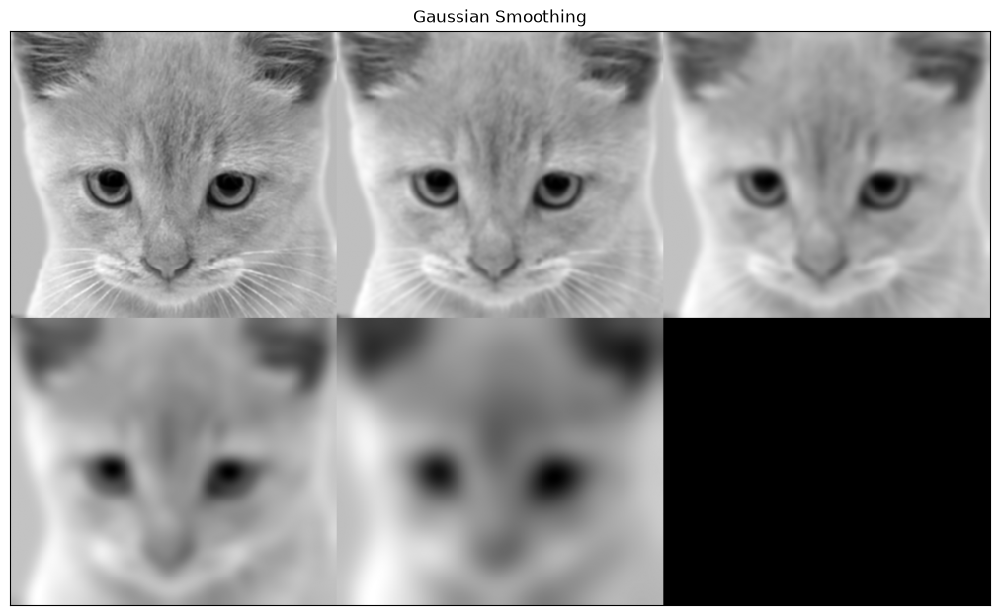

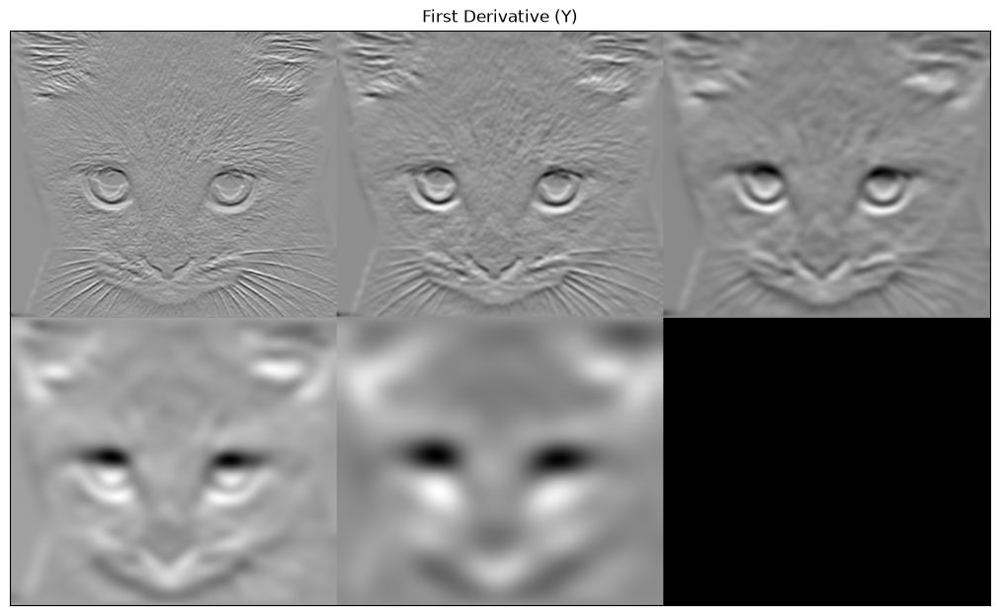

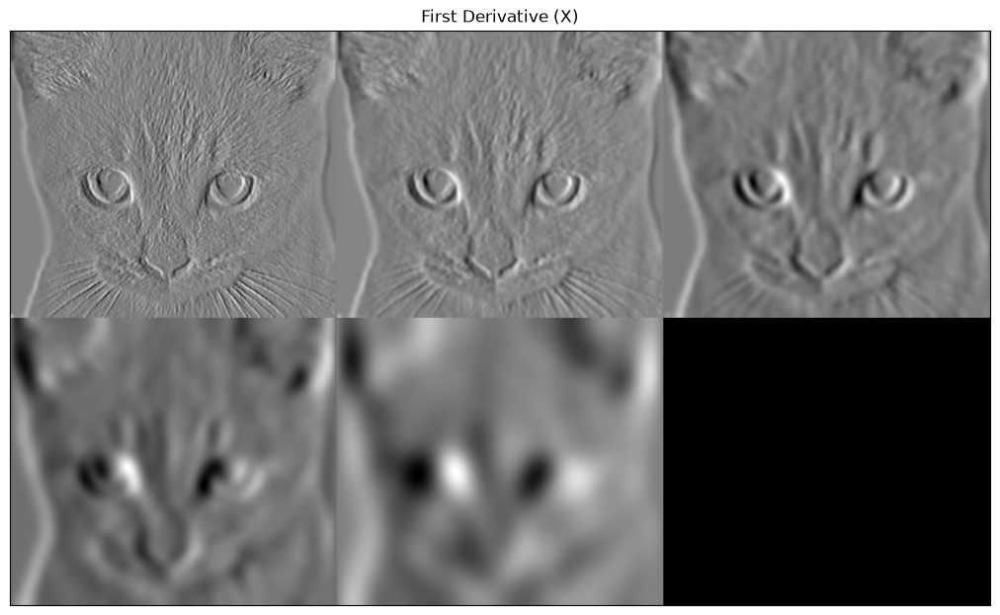

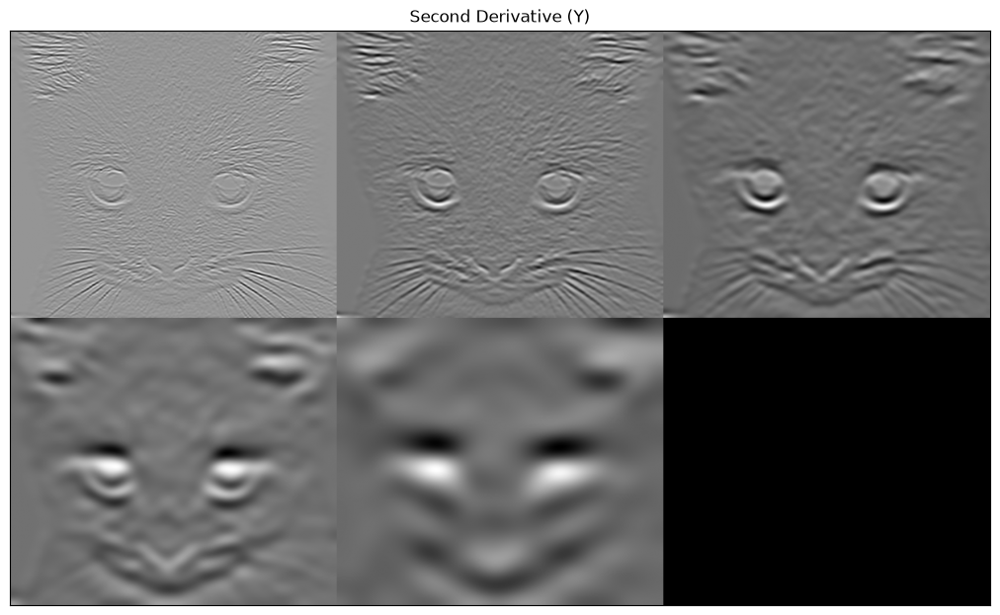

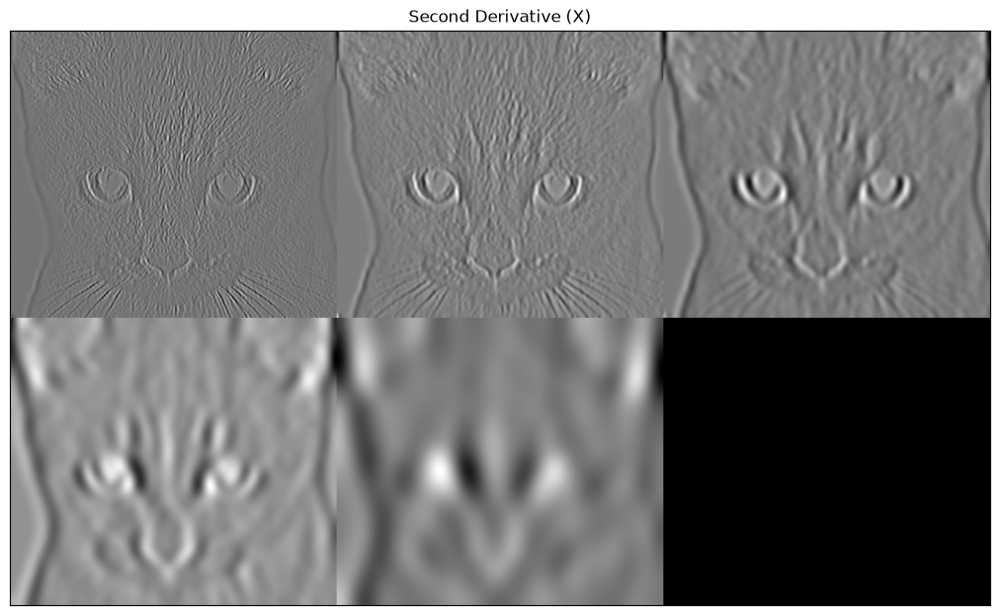

In [8]:
"""
    Apply Gaussian filtering or Gaussian-derivative filtering to an image.

    The function must construct the appropriate 1D Gaussian kernels (Gaussian,
    first derivative, or second derivative) for the given value of sigma and
    combine them using separable filtering.

    The parameter `orders` specifies the derivative order along the X and Y
    directions, respectively.
"""

def my2DConv(im, sigma, orders):
  # Máscaras 1D de la P1 para los órdenes 0, 1 y 2, volteadas porque sepFilter2D correlaciona
  masks = [gaussianMask1D(sigma=sigma, order=d)[::-1] for d in range(3)]
  if orders==[0,0]: # Suavizado Gaussiano
    return cv2.sepFilter2D(im.astype(np.float64), cv2.CV_64F, masks[0], masks[0])
  elif orders in ([1,0], [0,1], [2,0], [0,2], [1,1]):
    # kernelX (por filas) = derivada de orden orders[0]; kernelY (por columnas) = orders[1]
    return cv2.sepFilter2D(im.astype(np.float64), cv2.CV_64F, masks[orders[0]], masks[orders[1]])
  else:
    print('error in order of derivative')

# Comprobación del signo: escalón negro -> blanco hacia la derecha, luego dI/dx > 0 y dI/dy = 0
escalon = np.zeros((51, 51)); escalon[:, 25:] = 255
print('Escalón: dI/dx =', round(my2DConv(escalon, 2, [1,0])[25, 25], 2), '| dI/dy =', round(my2DConv(escalon, 2, [0,1])[25, 25], 2))

im = readIm(get_image('cat.bmp'), 0)
sigmas = [1, 2, 4, 8, 16]
print('Tamaño T de la máscara para sigma =', sigmas, '->', [len(gaussianMask1D(sigma=s)) for s in sigmas])

serie = lambda orders: [rangeDisplay01(my2DConv(im, s, orders)) for s in sigmas]   # cada imagen a [0,1]
vim0, vim1, vim1_1, vim2, vim2_1 = serie([0,0]), serie([0,1]), serie([1,0]), serie([0,2]), serie([2,0])

# En cada figura: sigma = 1, 2, 4 (arriba) y 8, 16 (abajo). En las derivadas, gris = 0
displayMI_ES(vim0,'Gaussian Smoothing',2)
displayMI_ES(vim1,'First Derivative (Y)',2)
displayMI_ES(vim1_1,'First Derivative (X)',2)
displayMI_ES(vim2,'Second Derivative (Y)',2)
displayMI_ES(vim2_1,'Second Derivative (X)',2)

### Análisis (1A)

- **Signo.** El escalón da $\partial I/\partial x=99.22$ y $\partial I/\partial y=0$ (salida): la derivada es positiva donde la intensidad crece hacia la derecha, así que el volteo produce una convolución real. Sin voltear saldría $-99.22$, porque $g'$ es antisimétrica (deducción propia).
- **Tamaños.** $T=7, 13, 25, 49, 97$ (salida), que son los de $T=2\lceil3\sigma\rceil+1$. Por ejemplo, con $\sigma=16$: $k=\lceil48\rceil=48$ y $T=2\cdot48+1=97$.
- **Suavizado.** Con $\sigma=1$ se ven los bigotes y el pelo; con $\sigma=4$ apenas se distinguen; con $\sigma=16$ solo quedan manchas (ojos y orejas). Es un paso bajo, como se esperaba.
- **1.ª derivada.** $\partial I/\partial x$ marca los bordes verticales (laterales de ojos y nariz) y $\partial I/\partial y$ los horizontales (párpados, bigotes). Blanco = oscuro→claro y negro = claro→oscuro en la dirección de derivación ($y$ crece hacia abajo).
- **2.ª derivada.** Cada borde da una franja clara y otra oscura. Los bigotes, que son líneas claras (máximos de intensidad), salen negros, porque la 2.ª derivada en un máximo es negativa. Con $\sigma=8$ y $16$ responde a "manchas" del tamaño de la Gaussiana, como los ojos.

## <font color='blue'>B) (1 punto)

<font color='blue'>En este apartado hay que emplear la función `my2DConv()`, creada en el apartado anterior (y que, a su vez, emplea la función de OpenCV `sepFilter2D()`) con $\sigma=1.5$ para calcular y mostrar el gradiente (dos imágenes: magnitud y orientación) y la Laplaciana de la Gaussiana. Se debe explicar el trabajo realizado, incluyendo las expresiones matemáticas subyacentes y el análisis, al igual que en todos los ejercicios, relativo a si los resultados obtenidos se corresponden con lo esperado. Se emplea la misma imagen del apartado anterior: `cat.bmp`

### Teoría (1B)

- **Gradiente** $\nabla I=(I_x,I_y)$: magnitud $\sqrt{I_x^2+I_y^2}$ (fuerza del borde) y orientación $\theta=\operatorname{atan2}(I_y,I_x)$, perpendicular al borde y hacia el lado claro (`2.2`, d. 35 y 76). Se usan derivadas de Gaussiana, que suavizan y derivan a la vez (`2.2`, d. 44-46).
- **Laplaciana de Gaussiana:** $\nabla^2G=g''(x)\,g(y)+g(x)\,g''(y)$ (`2.2`, d. 64; `Assignment2`, d. 24). Su kernel 2D no es separable (rango 2), pero es la suma de dos kernels separables (rango 1): cuatro convoluciones 1D (`Assignment2`, d. 21-27). Se comprueba frente a `filter2D` con el kernel 2D completo.

**Qué se espera:** magnitud alta solo en los contornos; orientación ruidosa en las zonas planas; LoG $\approx0$ en las zonas planas y doble línea $\pm$ en los bordes (paso banda, `2.3`, d. 62).

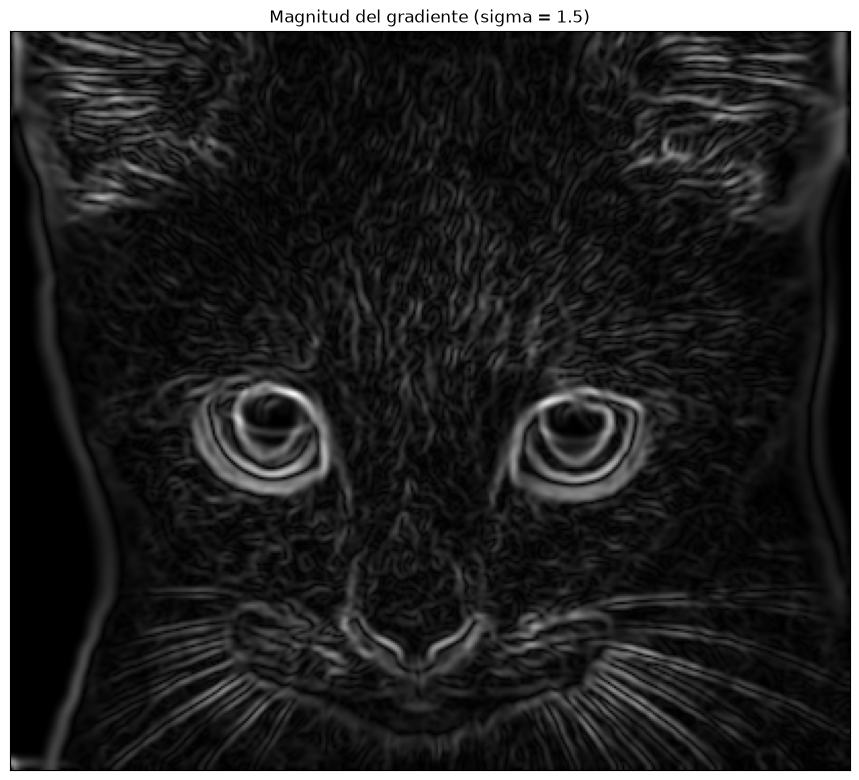

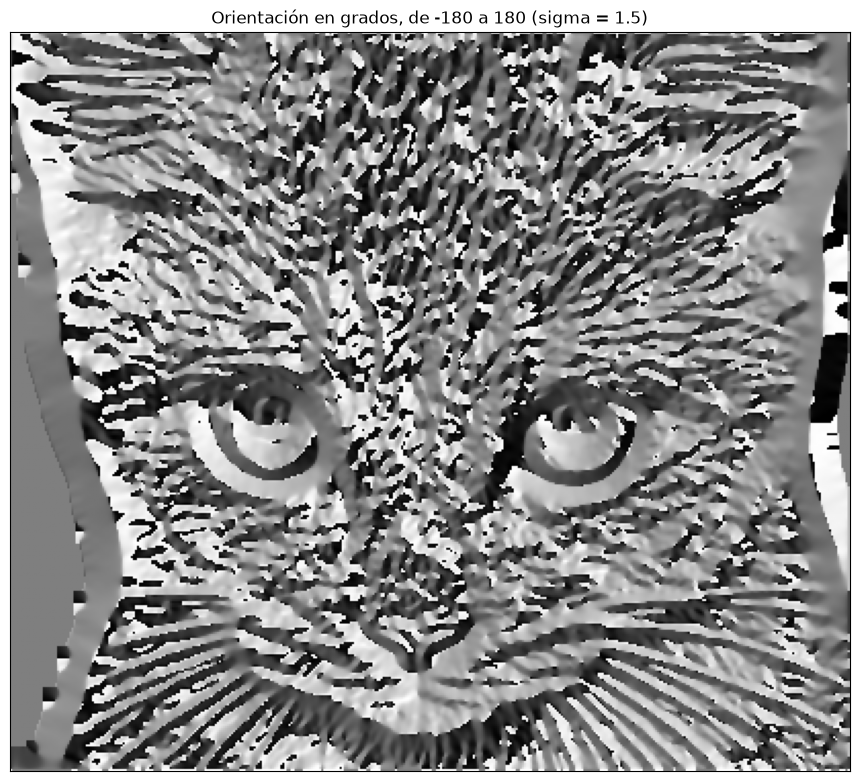

Kernel 2D: (11, 11) | rango: 2 | rango de cada sumando: 1
Máx. diferencia LoG separable vs. 2D: 5.684341886080802e-14


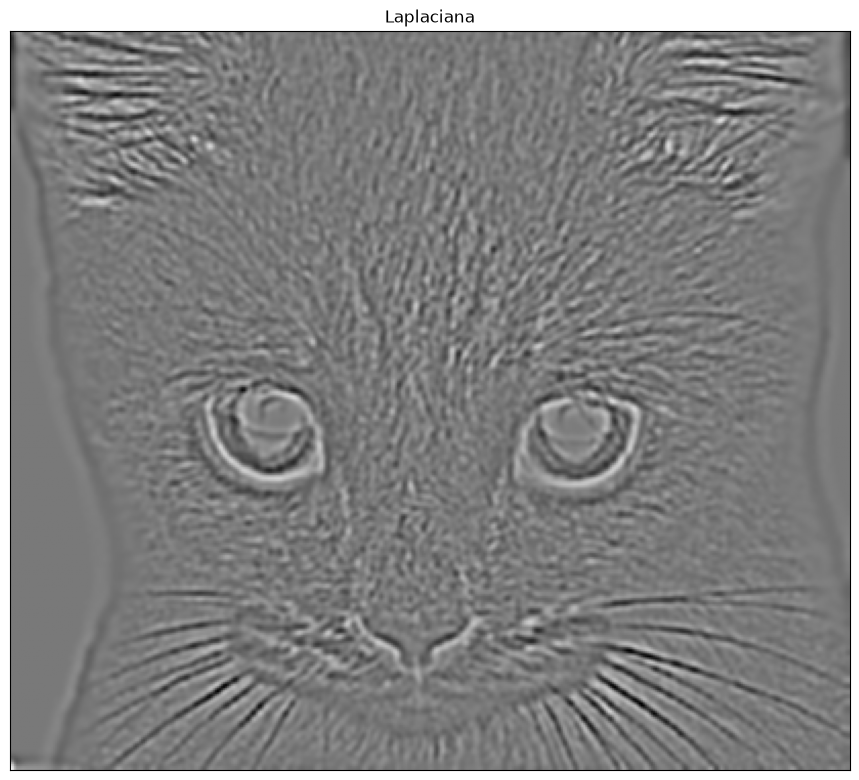

In [9]:
# https://pyimagesearch.com/2021/05/12/image-gradients-with-opencv-sobel-and-scharr/
# print(math.atan2(-255,0)*180/math.pi)
# print(math.pi/2)

"""
gradientIM applies my2Dconv to compute the derivatives in the x and y directions,
which are returned as dx and dy, respectively.
"""
def gradientIM(im,sigma, displayImages=False):
  dx, dy = my2DConv(im, sigma, [1,0]), my2DConv(im, sigma, [0,1])
  if displayImages:
    displayIm(np.sqrt(dx**2 + dy**2), f'Magnitud del gradiente (sigma = {sigma})')
    displayIm(np.degrees(np.arctan2(dy, dx)), f'Orientación en grados, de -180 a 180 (sigma = {sigma})')
  return dx,dy

"""
laplacianG uses calls to my2Dconv to compute and return the Laplacian of the Gaussian.
"""
def laplacianG(im,sigma):
  return my2DConv(im, sigma, [2,0]) + my2DConv(im, sigma, [0,2])   # las máscaras ya llevan sigma^2

im = readIm(get_image('cat.bmp'), 0)
sigma = 1.5
dx, dy = gradientIM(im, sigma, displayImages=True)

# Verificación: LoG separable frente a filter2D con el kernel 2D completo g(y)g''(x) + g''(y)g(x)
g, g2 = gaussianMask1D(sigma=sigma), gaussianMask1D(sigma=sigma, order=2)
K = np.outer(g, g2) + np.outer(g2, g)
print('Kernel 2D:', K.shape, '| rango:', np.linalg.matrix_rank(K), '| rango de cada sumando:', np.linalg.matrix_rank(np.outer(g, g2)))
print('Máx. diferencia LoG separable vs. 2D:', np.abs(laplacianG(im, sigma) - cv2.filter2D(im.astype(np.float64), cv2.CV_64F, K)).max())

displayIm(laplacianG(im,sigma),'Laplaciana')

### Análisis (1B)

- **Magnitud.** Es alta en ojos, nariz, bigotes y pelo, y casi negra en las zonas uniformes, como se esperaba.
- **Orientación.** Parece ruido porque `atan2` devuelve un ángulo también donde el gradiente es casi nulo. Sobre los bordes sí es coherente: alrededor de cada ojo pasa por todos los grises, porque el gradiente gira 360° al recorrer un contorno cerrado.
- **LoG.** Con $\sigma=1.5$ el kernel mide $11\times11$ ($k=\lceil4.5\rceil=5$). Tiene rango 2 y cada sumando rango 1, y la diferencia con la versión 2D es $5.7\cdot10^{-14}$ (salida): son equivalentes salvo redondeo. La versión separable hace $4\cdot11=44$ multiplicaciones por píxel frente a $11^2=121$ (cálculo propio). Visualmente es gris en las zonas planas y da dobles líneas $\pm$ en los bordes, cuyo paso por cero marca el borde (`2.2`, d. 48).

## <font color='blue'>C) (1 punto)  

<font color='blue'>Implemente una función para realizar "a mano" la convolución separable (es decir, empleando kernels 1D). Dicha función debe recibir como entrada una imagen (con el _padding_ adecuado, en caso de que lo necesite, ya incorporado) y un kernel 1D, y debe proporcionar como salida la imagen convolucionada con el kernel en ambas direcciones.

<font color='blue'>En esencia, la idea es que `convolve2D(image, kx, ky)` llame internamente dos veces a `convolve1D(image,kernel)`, una para realizar la convolución por filas y otra por columnas. En relación al padding, el hecho de introducirlo, o no, es un elemento externo a la función de convolución (que lo único que hace es realizar la convolución separable encajando el kernel hasta el límite de la imagen de entrada). El resultado de `convolve2D(image, kx, ky)` debe ser una imagen del mismo tamaño de la imagen de entrada `image` (que, como decimos, se asume que ya incluye el padding necesario).

<font color='blue'>Una vez haya implementado la función, aplique un kernel de derivadas en $X$ a la imagen `cat.bmp` (usando los kernels de tamaño $5$, generados por nuestras propias funciones de discretización, y dejando que sea la función de creación del kernel la que determine el $\sigma$ adecuado), y compare el resultado con el de `cv2.Sobel` (en donde se debe optar por la misma estrategia: fijando $ksize=5$, de modo que OpenCV construya automáticamente los kernels 1D correspondientes al operador de Sobel de ese tamaño). ¿Hay diferencias (sea a nivel de resultado final o de tiempo de ejecución)? En caso afirmativo, ¿a qué se pueden deber?

<font color='blue'>**Nota1**: el código del alumnado no puede ser más de $25$ veces más lento que el de OpenCV. Ese es el límite superior aceptable. Se debe optimizar la ejecución para, al menos, estar en ese orden de magnitud comparativamente con el rendimiento ofrecido por OpenCV. Estos tiempos de ejecución se deben medir usando:

```python
starttime = time.perf_counter()
# CÓDIGOS DE CONVOLUCIÓN
duration = timedelta(seconds=time.perf_counter() - starttime)
```
<font color='blue'>En el fragmento de código anterior, en donde se indica cómo medir el tiempo, cuando hablamos de `CÓDIGOS DE CONVOLUCIÓN` nos referimos única y exclusivamente a la llamada a `convolve2D`.

<font color='blue'>**Nota2:** no se puede utilizar en todo el ejercicio ni `from numpy.lib.stride_tricks import sliding_window_view` ni `np.convolve`.


### Teoría (1C)

- **`convolve1D`** convoluciona por filas con **un único bucle, sobre los coeficientes del kernel**: en cada iteración suma, de golpe para todos los píxeles, la contribución de un coeficiente. La salida es un array nuevo, no se calcula *in place* (`Assignment2`, d. 29), y solo se rellena donde el kernel cabe entero (modo *valid*, `2.1`, d. 73).
- **`convolve2D`** aplica `kx` por filas y `ky` por columnas, trasponiendo la imagen (`Assignment2`, d. 30-31).
- **Padding externo** con `BORDER_REFLECT_101`, el que usa OpenCV por defecto, para que la comparación con `cv2.Sobel` sea justa también en los bordes.

**Hipótesis.** Sobel de tamaño 5 combina el suavizado $[1,4,6,4,1]$ y la derivada $[-1,-2,0,2,1]$, sin normalizar (`2.2`, d. 52-57). Nuestras máscaras de tamaño 5 usan $\sigma=(5-1)/6=0.667$ y sí están normalizadas. Esperamos el mismo patrón de bordes con distinta escala y distinto suavizado, y que OpenCV (C++) sea más rápido.

In [10]:
def convolve1D(image,kernel):
    # Convolución por filas. La entrada ya trae el padding; solo se calcula donde el kernel cabe
    # entero y los r píxeles de cada extremo quedan a 0 (se recortan fuera)
    k = np.asarray(kernel, dtype=np.float64)[::-1]      # convolución = kernel volteado
    r, W = len(k) // 2, image.shape[1]
    output = np.zeros(image.shape)                      # salida separada de la entrada
    for j in range(len(k)):                             # un único bucle, sobre los coeficientes
        output[:, r:W-r] += k[j] * image[:, j:j+W-2*r]
    return output

def convolve2D(image, kx, ky):
    output2 = convolve1D(convolve1D(image, kx).T, ky).T  # filas con kx, columnas con ky
    return output2

Una ejecución -> convolve2D: 0:00:00.002372 | cv2.Sobel: 0:00:00.000346
Mediana de 100 -> convolve2D: 1.61 ms | cv2.Sobel: 0.19 ms | 8.5 veces más lenta (límite: 25)

Nuestros kernels -> kx: [ 0.0199  0.2913 -0.     -0.2913 -0.0199] | ky: [0.0066 0.1942 0.5983 0.1942 0.0066]
Kernels de Sobel -> derivada: [-1. -2.  0.  2.  1.] | suavizado: [1. 4. 6. 4. 1.]
Máx. diferencia con sepFilter2D (mismos kernels): 1.709743457922741e-14
Máx. diferencia con cv2.Sobel (sus coeficientes, volteados, en convolve2D): 0.0
Respuesta a una rampa de pendiente 1 -> nuestra: 0.6624 | Sobel: 128.0
Correlación de Pearson entre ambos resultados: 0.9719


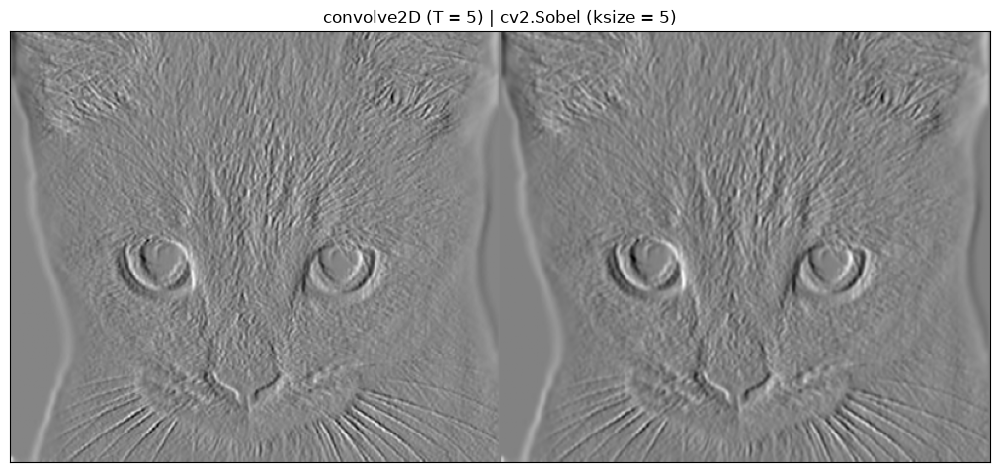

In [11]:
import time
from datetime import timedelta

im = readIm(get_image('cat.bmp'), 0).astype(np.float64)
kx = gaussianMask1D(sizeMask=5, order=1)   # derivada en X (sigma = 4/6)
ky = gaussianMask1D(sizeMask=5, order=0)   # suavizado en Y
r = 2
im_pad = cv2.copyMakeBorder(im, r, r, r, r, cv2.BORDER_REFLECT_101)

starttime = time.perf_counter()
nuestra = convolve2D(im_pad, kx, ky)[r:-r, r:-r]
duration = timedelta(seconds=time.perf_counter() - starttime)
starttime = time.perf_counter()
sobel = cv2.Sobel(im, cv2.CV_64F, 1, 0, ksize=5)
duration_cv = timedelta(seconds=time.perf_counter() - starttime)
print('Una ejecución -> convolve2D:', duration, '| cv2.Sobel:', duration_cv)

def mediana(f, n=100):   # una sola medida es muy ruidosa: mediana de n repeticiones
  t = []
  for _ in range(n):
    s = time.perf_counter(); f(); t.append(time.perf_counter() - s)
  return np.median(t)
t1, t2 = mediana(lambda: convolve2D(im_pad, kx, ky)), mediana(lambda: cv2.Sobel(im, cv2.CV_64F, 1, 0, ksize=5))
print(f'Mediana de 100 -> convolve2D: {t1*1e3:.2f} ms | cv2.Sobel: {t2*1e3:.2f} ms | {t1/t2:.1f} veces más lenta (límite: 25)')

# Verificaciones
sob_d, sob_s = [k.ravel() for k in cv2.getDerivKernels(1, 0, 5)]
print('\nNuestros kernels -> kx:', np.round(kx, 4), '| ky:', np.round(ky, 4))
print('Kernels de Sobel -> derivada:', sob_d, '| suavizado:', sob_s)
print('Máx. diferencia con sepFilter2D (mismos kernels):', np.abs(nuestra - cv2.sepFilter2D(im, cv2.CV_64F, kx[::-1], ky[::-1])).max())
print('Máx. diferencia con cv2.Sobel (sus coeficientes, volteados, en convolve2D):', np.abs(convolve2D(im_pad, sob_d[::-1], sob_s)[r:-r, r:-r] - sobel).max())
rampa = np.tile(np.arange(40.0), (40, 1))   # I(x,y) = x: pendiente 1
print('Respuesta a una rampa de pendiente 1 -> nuestra:', round(convolve2D(cv2.copyMakeBorder(rampa, r, r, r, r, cv2.BORDER_REFLECT_101), kx, ky)[22, 22], 4),
      '| Sobel:', cv2.Sobel(rampa, cv2.CV_64F, 1, 0, ksize=5)[20, 20])
print('Correlación de Pearson entre ambos resultados:', round(np.corrcoef(nuestra.ravel(), sobel.ravel())[0, 1], 4))
displayMI_ES([rangeDisplay01(nuestra), rangeDisplay01(sobel)], 'convolve2D (T = 5) | cv2.Sobel (ksize = 5)', 2)

### Análisis (1C)

- **Corrección.** Con los mismos kernels, `convolve2D` y `sepFilter2D` difieren en $1.7\cdot10^{-14}$ (redondeo), y con los coeficientes de Sobel volteados reproduce `cv2.Sobel` exactamente: diferencia $0.0$ (salida). Como `convolve2D` vuelve a voltear el kernel, lo que se aplica es una correlación con $[-1,-2,0,2,1]$: así es como lo hace Sobel (`2.1`, d. 70).
- **Diferencias en el resultado: se deben solo a los kernels.**
  - *Suavizado:* el binomial $[1,4,6,4,1]/16$ tiene varianza $\frac{4+4+0+4+4}{16}=1$, es decir, $\sigma=1$ (cálculo propio), frente a nuestro $\sigma=0.667$: **Sobel suaviza más**.
  - *Escala:* ante una rampa de pendiente 1, el nuestro da $0.6624\approx\sigma$ (derivada normalizada) y Sobel $128$ (salida), porque no está normalizado: $[-1,-2,0,2,1]$ sobre la rampa da $2+2+0+2+2=8$, y el suavizado multiplica por $1+4+6+4+1=16$; $8\cdot16=128$ (cálculo propio).
  - *Estructura:* la correlación de Pearson es $0.9719$ (salida). Resaltan los mismos bordes, pero no son idénticos ni corrigiendo la escala.
- **Tiempo.** Con la mediana de 100 repeticiones nuestra función es varias veces más lenta que `cv2.Sobel` (la cifra exacta está en la salida y cambia con la máquina y la carga; en las ejecuciones locales ha estado entre 5 y 9), muy por debajo del límite de 25. OpenCV está en C++ con SIMD; la nuestra crea un array temporal por coeficiente y recorre la imagen 10 veces (5 coeficientes × 2 direcciones).

# <font color='blue'>**Ejercicio 2**:  Pirámides Gaussianas y Laplacianas (4.5 puntos)







## <font color='blue'>A) (1 punto)

<font color='blue'>Construya una pirámide Gaussiana de $4$ niveles empleando máscaras Gaussianas de tamaño $7\times7$. Recuérdese que, cuando hablamos de $x$ niveles, nos referimos a la imagen original más $x$ niveles adicionales. Esta convención se aplicará tanto en este ejercicio como en el resto de la práctica. No se permite utilizar las funciones `pyrUp()` ni `pyrDown()` de OpenCV. Asimismo, `cv2.resize()` no podrá emplearse para construir la pirámide Gaussiana en el apartado A, aunque sí podrá utilizarse para construir la pirámide Laplaciana en el apartado B y para reconstruir la imagen original a partir de esta última en el apartado C. En todos los apartados de este ejercicio deberá utilizarse la imagen `motorcycle.bmp`. </font>

### Teoría (2A)

Submuestrear sin filtrar produce *aliasing*: las frecuencias por encima del nuevo límite de Nyquist se "pliegan" y aparecen como patrones falsos (`2.3`, d. 10-16). Por eso cada nivel se calcula como $G_{i+1}=(H*G_i)\!\downarrow_2$: primero se suaviza con una Gaussiana y después se toman las filas y columnas pares (`2.3`, d. 17-22). En el límite, la pirámide ocupa $1+\frac14+\frac1{16}+\dots=\frac43$ de la original (`2.3`, d. 22).

- Máscara de tamaño 7, es decir, $\sigma=(7-1)/6=1$, aplicada como dos 1D con `sepFilter2D`; submuestreo con `[::2, ::2]`. Ni `pyrDown` ni `resize`.
- "4 niveles" = la original más 4 niveles, 5 imágenes (convención del enunciado).

In [12]:
'''
This function displays a pyramid of images, providing as input the list of images to display.

Example of use:
im1 = readIm(get_image('apple.jpg'), 1)
images = [
    im1,
    cv2.resize(im1, (im1.shape[1]//2,  im1.shape[0]//2),  interpolation=cv2.INTER_LINEAR),
    cv2.resize(im1, (im1.shape[1]//4,  im1.shape[0]//4),  interpolation=cv2.INTER_LINEAR),
    cv2.resize(im1, (im1.shape[1]//8,  im1.shape[0]//8),  interpolation=cv2.INTER_LINEAR),
    cv2.resize(im1, (im1.shape[1]//16, im1.shape[0]//16), interpolation=cv2.INTER_LINEAR)
]
displayPyramid(images, title='Piramide de Manzanas')
'''
def displayPyramid(vim, title='result'):
  temp = np.zeros_like(vim[0])
  if np.mod(temp.shape[1],2)==0:
    h = temp[:, :temp.shape[1]//2]
  else:
    h = temp[:, :(temp.shape[1]//2)+1]
  out = np.hstack((temp, h))
  top = 0
  out[0:vim[0].shape[0], 0:vim[0].shape[1]] = vim[0]
  left = vim[0].shape[1]
  for i in range(1, len(vim)):
    out[top:top+vim[i].shape[0], left:left + vim[i].shape[1]] = vim[i]
    top += vim[i].shape[0]
  displayIm(out, title)

Tamaños: [(300, 453), (150, 227), (75, 114), (38, 57), (19, 29)]
Píxeles de la pirámide / píxeles de la original: 1.3335


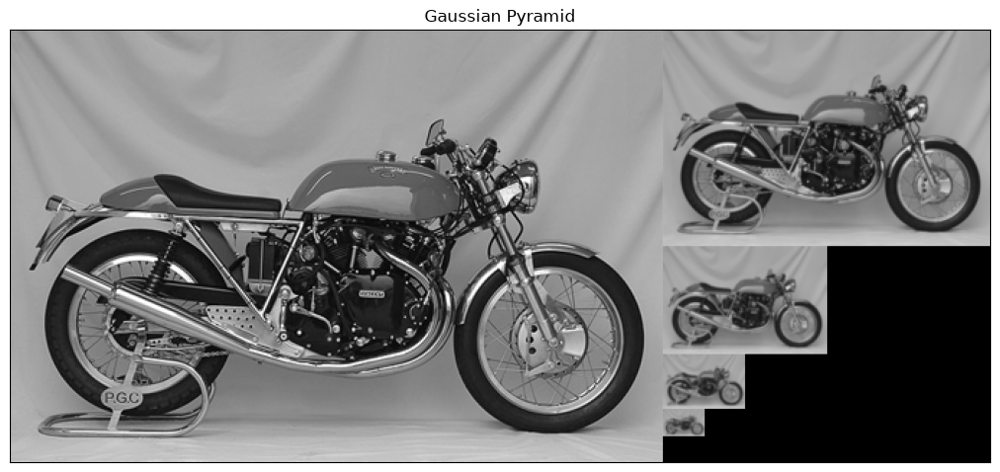

In [13]:
def pyramidGauss(im,sizeMask=7, nlevel=4):
  mask = gaussianMask1D(sizeMask=sizeMask)              # simétrica: correlación = convolución
  vim = [im.astype(np.float64)]
  for _ in range(nlevel):
    vim.append(cv2.sepFilter2D(vim[-1], cv2.CV_64F, mask, mask)[::2, ::2])   # suavizar y submuestrear
  return vim

im = readIm(get_image('motorcycle.bmp'), 0)
pyrG = pyramidGauss(im, 7, 4)
print('Tamaños:', [g.shape for g in pyrG])
print('Píxeles de la pirámide / píxeles de la original:', round(sum(g.size for g in pyrG) / im.size, 4))
displayPyramid(pyrG,'Gaussian Pyramid')

### Análisis (2A)

- **Tamaños.** De $300\times453$ a $19\times29$ (salida). Cada nivel tiene la mitad de filas y columnas, redondeando hacia arriba cuando son impares ($453\to227$), porque `[::2]` de $n$ elementos devuelve $\lceil n/2\rceil$.
- **Memoria.** La pirámide ocupa $1.3335$ veces la original (salida), prácticamente el límite de $4/3$ (`2.3`, d. 22).
- **Visual.** Cada nivel conserva la forma de la moto (ruedas, depósito) y pierde detalle fino (radios, matrícula) sin dientes de sierra: el suavizado previo evita el *aliasing*. El apartado 2D.2 lo contrasta con una pirámide sin suavizar.

## <font color='blue'>B) (1 punto)

<font color='blue'>Use su código del apartado anterior para implementar una función que permita construir la pirámide Laplaciana asociada. Junto con la pirámide, debe mostrarse, para cada nivel, las imágenes a las que se les calcula la diferencia y el resultado de dicha diferencia.

### Teoría (2B)

$$L_i=G_i-\operatorname{expand}(G_{i+1}),\quad i=0,\dots,n-1,\qquad L_n=G_n$$

(`2.3`, d. 25-26; `Assignment2`, d. 39 y 46). Cada $L_i$ guarda lo que la expansión del nivel superior no es capaz de predecir: una banda de frecuencias, como una diferencia de Gaussianas (`2.2`, d. 69). La cima se guarda sin restar, porque hace falta para reconstruir. `expand` es `cv2.resize` bilineal al tamaño exacto de $G_i$.

**Qué se espera:** niveles con media $\approx0$ (gris) que solo contienen bordes, cada vez más gruesos, y una cima que es una miniatura borrosa.

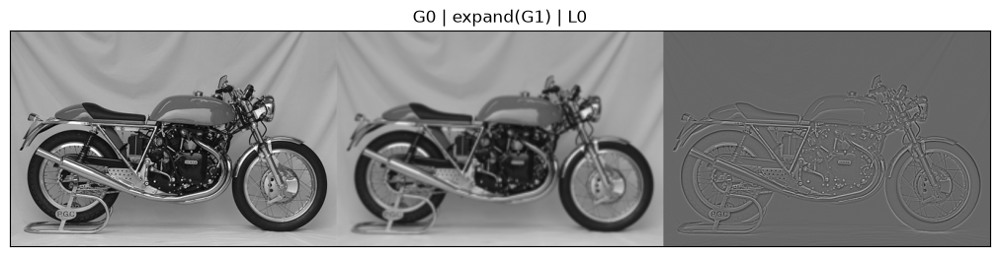

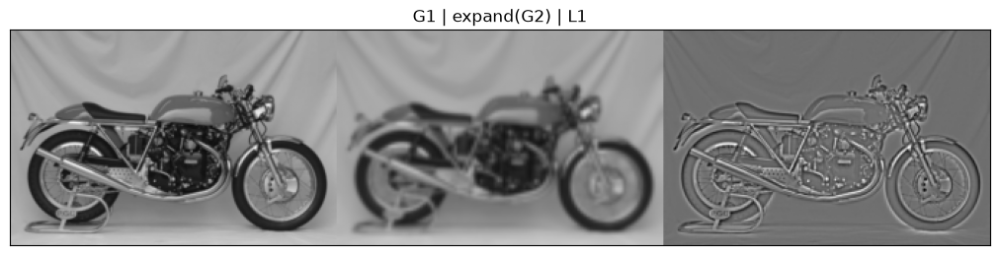

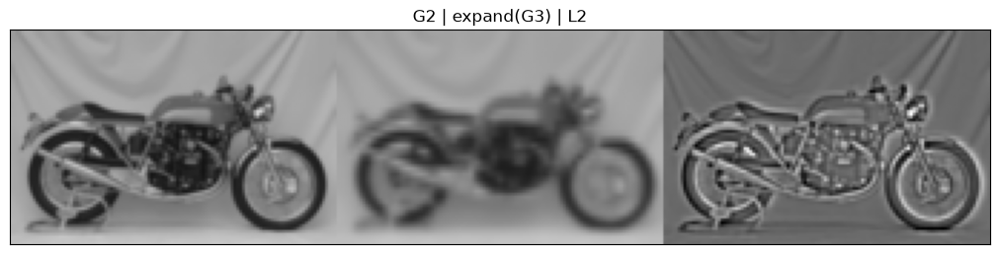

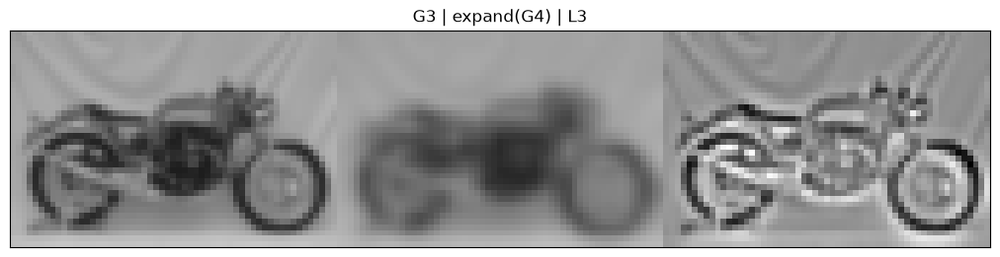

Media de cada nivel (L0..L3, cima): [0.0, -0.04, -0.58, -0.05, 131.73]
Rango de L0: -136.55 a 201.9


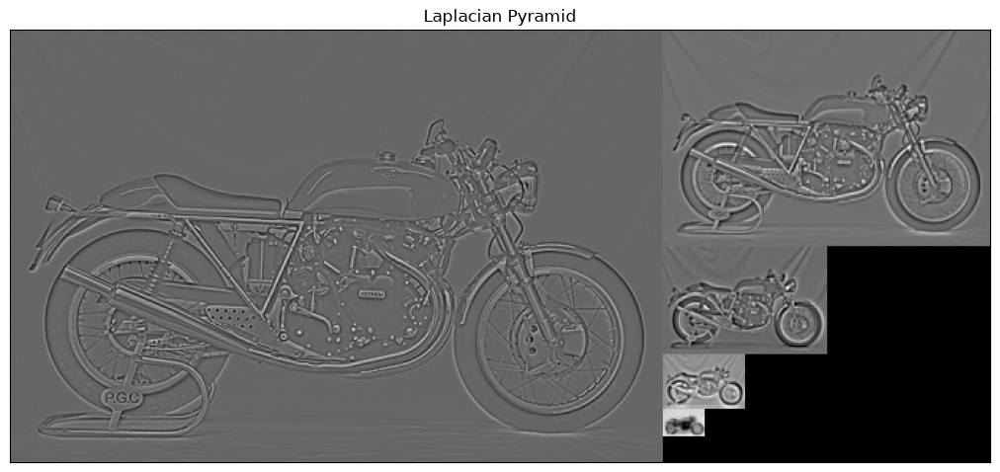

In [14]:
def expandIm(img, shape, flagInterp):
  # flagInterp: constante de cv2.resize, o 'pyrUp' (solo para la comparación del apartado 2D.1)
  h, w = shape[:2]
  if flagInterp == 'pyrUp':
    return cv2.pyrUp(img, dstsize=(w, h))
  return cv2.resize(img, (w, h), interpolation=flagInterp)

def laplacianFromGauss(pyrG, flagInterp):
  return [pyrG[i] - expandIm(pyrG[i+1], pyrG[i].shape, flagInterp) for i in range(len(pyrG) - 1)] + [pyrG[-1]]

def pyramidLap(im, sizeMask,nlevel,flagInterpLap, displaySteps=False):
  pyrG = pyramidGauss(im, sizeMask, nlevel)
  vimL = laplacianFromGauss(pyrG, flagInterpLap)
  if displaySteps:   # para cada nivel: las dos imágenes que se restan y su diferencia
    for i in range(nlevel):
      e = expandIm(pyrG[i+1], pyrG[i].shape, flagInterpLap)
      displayMI_ES([pyrG[i] / 255, np.clip(e, 0, 255) / 255, rangeDisplay01(vimL[i])], f'G{i} | expand(G{i+1}) | L{i}', 2)
  return vimL

im = readIm(get_image('motorcycle.bmp'), 0)
pyrL = pyramidLap(im, 7, 4, cv2.INTER_LINEAR, displaySteps=True)
print('Media de cada nivel (L0..L3, cima):', [round(float(l.mean()), 2) for l in pyrL])
print('Rango de L0:', round(pyrL[0].min(), 2), 'a', round(pyrL[0].max(), 2))
displayPyramid([rangeDisplay01(l) for l in pyrL], 'Laplacian Pyramid')

### Análisis (2B)

- **Qué se resta.** $\operatorname{expand}(G_{i+1})$ es una versión más borrosa de $G_i$; su diferencia $L_i$ solo contiene bordes y texturas.
- **Bandas.** $L_0$ recoge el detalle más fino (radios, tornillos); $L_3$, los contornos gruesos (perfil de las ruedas, pliegues del fondo); la cima es una miniatura borrosa.
- **Media.** Los niveles Laplacianos tienen media entre $-0.58$ y $0.00$, frente a $131.73$ de la cima (salida): eliminan la componente continua, como corresponde a un paso banda.
- **Signo.** $L_0$ va de $-136.55$ a $201.90$ (salida), así que hay que trabajar en coma flotante: en `uint8` se perderían los negativos.

## <font color='blue'>C) (1 punto)

<font color='blue'>Implemente ahora una función para reconstruir la imagen codificada en la pirámide Laplaciana del apartado anterior. Verifique que es posible obtener una copia exacta de la imagen original. Para ello, calcule el error de reconstrucción como el _Root Mean Squared Error_ (RMSE) entre los niveles de intensidad de la imagen original y la imagen reconstruida (redondeando al entero más cercano: `np.round()`).

### Teoría (2C)

Despejando de la definición, $G_i=L_i+\operatorname{expand}(G_{i+1})$: se parte de la cima y se baja nivel a nivel hasta $G_0$ (`2.3`, d. 26 y 29; `Assignment2`, d. 47). Si al reconstruir se usa **la misma** expansión que al construir, el resultado es exacto con cualquier $\sigma$, tamaño de máscara o interpolación (`Assignment2`, d. 41 y 45: *"Sigma does not influence the reconstruction!"*). Solo queda el error de redondeo en coma flotante, que desaparece con `np.round()`. Se comprueba también con otras máscaras e interpolaciones.

Máx. error antes de redondear: 1.4210854715202004e-14


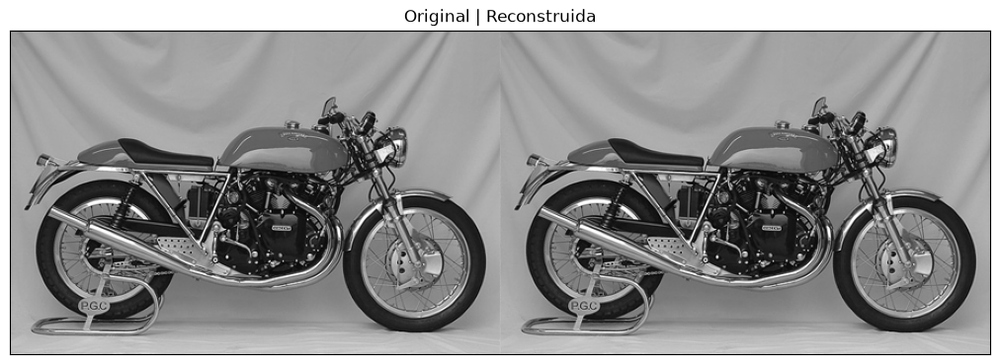

sizeMask =  3, NEAREST -> RMSE = 0.0
sizeMask =  3, CUBIC   -> RMSE = 0.0
sizeMask = 15, NEAREST -> RMSE = 0.0
sizeMask = 15, CUBIC   -> RMSE = 0.0
sizeMask = 31, NEAREST -> RMSE = 0.0
sizeMask = 31, CUBIC   -> RMSE = 0.0
Error per pixel 0.0


In [15]:
def reconstructLap(pyL,flagInterpReconstruct):
  im = pyL[-1]
  for L in pyL[-2::-1]:                                  # de la cima hacia la base
    im = L + expandIm(im, L.shape, flagInterpReconstruct)
  return im

def rmse(a, b):
  return np.sqrt(np.mean((a - np.round(b)) ** 2))

im = readIm(get_image('motorcycle.bmp'), 0).astype(np.float64)
recons = reconstructLap(pyramidLap(im, 7, 4, cv2.INTER_LINEAR), cv2.INTER_LINEAR)
print('Máx. error antes de redondear:', np.abs(im - recons).max())
displayMI_ES([im / 255, np.clip(recons, 0, 255) / 255], 'Original | Reconstruida', 2)

# Otras máscaras e interpolaciones (la misma al construir y al reconstruir)
for s in [3, 15, 31]:
  for nombre, f in [('NEAREST', cv2.INTER_NEAREST), ('CUBIC', cv2.INTER_CUBIC)]:
    print(f'sizeMask = {s:2d}, {nombre:7s} -> RMSE = {rmse(im, reconstructLap(pyramidLap(im, s, 4, f), f))}')

print('Error per pixel',np.sqrt(np.mean((im - np.round(recons)) ** 2)))

### Análisis (2C)

La reconstrucción es exacta: `Error per pixel 0.0` (salida). Antes de redondear el error máximo es $1.4\cdot10^{-14}$, que es redondeo de coma flotante ($(a-b)+b$ no siempre devuelve exactamente $a$). Con máscaras de 3, 15 y 31 y con interpolación por vecino más próximo o bicúbica el RMSE también es $0.0$ (salida). Se confirma `Assignment2` (d. 45): lo único que importa es usar la misma expansión en las dos fases.

## <font color='blue'>D) (1.5 puntos)



### <font color='blue'>APARTADO 1 (0.5 puntos)

<font color='blue'>Imaginemos ahora que no utilizamos el mismo procedimiento de expansión al construir la pirámide Laplaciana y al reconstruir la imagen original.En el primer caso, empleamos `cv2.resize()`, con `cv2.INTER_LINEAR`, mientras que en el segundo utilizamos `cv2.pyrUp()`. ¿Afecta esta diferencia al proceso de reconstrucción? ¿Por qué?

<font color='blue'>Se recomienda que, junto con la discusión de la respuesta y el razonamiento asociado, tanto en este apartado como en los siguientes, se aporte evidencia empírica que permita verificar/apoyar la hipótesis planteada por el alumno. Por ejemplo, puede desarrollarse un pequeño script que implemente la modificación propuesta en el enunciado y permita analizar experimentalmente sus efectos.

**Hipótesis: no será exacta.** La exactitud del 2C exige la misma expansión en las dos fases, y aquí difieren: `resize` bilineal interpola cada píxel destino a partir de sus 4 vecinos (`2.3`, d. 83), mientras que `pyrUp` inserta ceros, suaviza con una Gaussiana $5\times5$ y multiplica por 4 (`2.3`, d. 82). Cada paso deja un error $E_r(\hat G_{i+1})-E_c(G_{i+1})\neq0$, que además se acumula hacia la base porque $\hat G_{i+1}$ ya llega con error. Se comprueba con todas las combinaciones de expansión.

Construcción con resize LINEAR, reconstrucción con pyrUp -> Error per pixel 10.467570369164322

          NEAREST   LINEAR    CUBIC    pyrUp
 NEAREST     0.00    15.07    17.36    20.45
  LINEAR    18.50     0.00     8.55    10.47
   CUBIC    18.21     7.84     0.00    14.69
   pyrUp    24.10    10.77    16.52     0.00


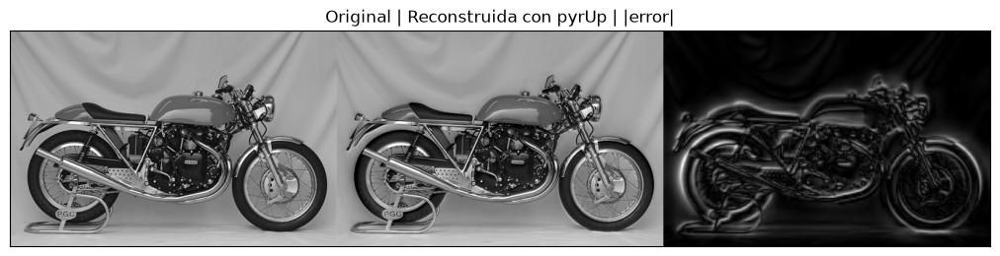

In [16]:
recons_up = reconstructLap(pyramidLap(im, 7, 4, cv2.INTER_LINEAR), 'pyrUp')
print('Construcción con resize LINEAR, reconstrucción con pyrUp -> Error per pixel', rmse(im, recons_up))

# RMSE de todas las combinaciones (filas: construcción | columnas: reconstrucción)
metodos = {'NEAREST': cv2.INTER_NEAREST, 'LINEAR': cv2.INTER_LINEAR, 'CUBIC': cv2.INTER_CUBIC, 'pyrUp': 'pyrUp'}
print('\n' + ' ' * 8 + ''.join(f'{n:>9}' for n in metodos))
for nc, fc in metodos.items():
  L = pyramidLap(im, 7, 4, fc)
  print(f'{nc:>8}' + ''.join(f'{rmse(im, reconstructLap(L, fr)):9.2f}' for fr in metodos.values()))

displayMI_ES([im / 255, np.clip(recons_up, 0, 255) / 255, rangeDisplay01(np.abs(im - recons_up))], 'Original | Reconstruida con pyrUp | |error|', 2)

#### Respuesta (2D.1)

**Sí afecta: el error pasa de $0.0$ a $10.47$** (salida). En la tabla, la diagonal (mismo método en las dos fases) es siempre $0$, también con `pyrUp`→`pyrUp`, y fuera de ella el error está entre $7.84$ y $24.10$ (salida). Así que ningún método es "mejor": lo que rompe la reconstrucción es usar dos distintos. El error se concentra en los contornos de la moto, que es donde más difieren dos interpolaciones; en las zonas uniformes cualquier método da lo mismo. Coincide con lo visto en clase: "no se consigue".

### <font color='blue'>APARTADO 2 (0.5 puntos)

<font color='blue'>¿Es posible reconstruir a la perfección (`Error per pixel 0.0`) la imagen original por medio de una pirámide Laplaciana construida a partir de una pirámide Gaussiana sin suavizado (es decir, una pirámide no realmente Gaussiana, construida exclusivamente en base a hacer subsampling)?

**Hipótesis: sí será exacta.** El razonamiento del 2C no usa en ningún momento que $G_{i+1}$ esté suavizado, solo que la expansión sea la misma en las dos fases. Lo que cambia es la calidad: sin el paso bajo habrá *aliasing* (`2.3`, d. 23; `Assignment2`, d. 38). Se reconstruye y se compara el nivel 3 con y sin suavizado.

Pirámide sin suavizado -> Error per pixel 0.0


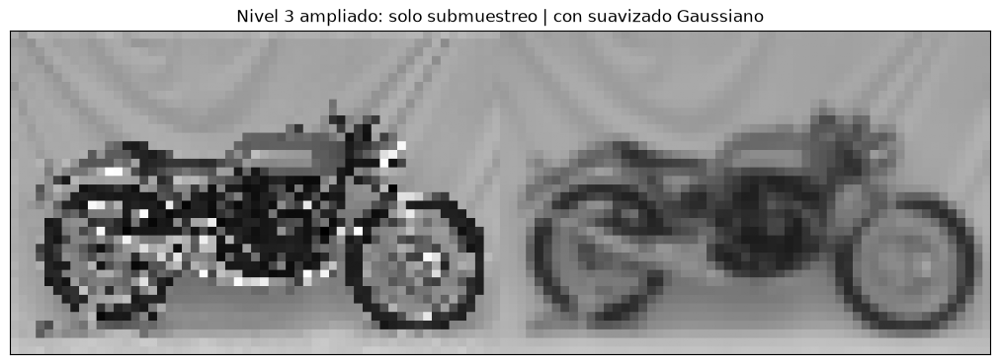

In [17]:
pyrS = [im]
for _ in range(4):
  pyrS.append(pyrS[-1][::2, ::2])                        # solo submuestreo, sin suavizar
print('Pirámide sin suavizado -> Error per pixel', rmse(im, reconstructLap(laplacianFromGauss(pyrS, cv2.INTER_LINEAR), cv2.INTER_LINEAR)))

zoom = lambda x: cv2.resize(x, im.shape[::-1], interpolation=cv2.INTER_NEAREST) / 255   # x8, sin interpolar
displayMI_ES([zoom(pyrS[3]), zoom(pyramidGauss(im, 7, 4)[3])], 'Nivel 3 ampliado: solo submuestreo | con suavizado Gaussiano', 2)

#### Respuesta (2D.2)

**Sí: `Error per pixel 0.0`** (salida), como en las notas de clase ("sí"). La reconstrucción solo depende de que $L_i$ guarde el residuo de la misma expansión que se usa al reconstruir. Pero la pirámide pierde calidad: en el nivel 3 sin suavizar los radios aparecen rotos, los contornos tienen dientes de sierra y quedan brillos sueltos del cromado, mientras que la versión Gaussiana es borrosa pero coherente. Es el *aliasing* de `2.3` (d. 23).

### <font color='blue'>APARTADO 3 (0.5 puntos)

<font color='blue'>Intentemos ahora crear la pirámide Laplaciana de "abajo a arriba". Es decir, tal y como hemos visto en teoría, la pirámide Gaussiana se construye de "abajo a arriba", y la Laplaciana se construye de "arriba a abajo" (desde la cima de la pirámide hacia la base). Pero, ¿qué pasa si la Laplaciana también se construye de "abajo a arriba"? Hablamos de partir de la imagen original y construir la Gaussiana y la Laplaciana al mismo tiempo, de "abajo a arriba" simultáneamente:
1) Suavizo la imagen original, calculo la resta de la original y su suavizada. Y con eso ya tengo el "nivel de abajo" de la pirámide Laplaciana.
2) Submuestreo la imagen original suavizada (y ya tengo el siguiente nivel de la pirámide Gaussiana). Resto esa imagen a una versión suavizada de la misma. Y con eso ya tengo el siguiente nivel de la pirámide Laplaciana.
3) Así sucesivamente.

<font color='blue'>En otras palabras: en lugar de definir cada nivel como la diferencia entre $G_i$ y la expansión del siguiente nivel gaussiano $G_{i+1}$, calculamos directamente la diferencia entre $G_i$ y su versión suavizada $H(G_i)$. Después, submuestreamos $H(G_i)$ para obtener $G_{i+1}$ y repetimos el proceso. ¿Esto sería un proceso válido para construir la pirámide Laplaciana? ¿Nos seguiría permitiendo reconstruir la imagen de entrada?



**Planteamiento.** Aquí $L_i=G_i-H(G_i)$ y $G_{i+1}=H(G_i)\!\downarrow_2$. Para reconstruir haría falta $H(G_i)$ a resolución completa, pero solo se guarda su versión submuestreada:

$$L_i+\operatorname{expand}(G_{i+1})=G_i-\big[H(G_i)-\operatorname{expand}\big(H(G_i)\!\downarrow_2\big)\big]$$

**Hipótesis: no será exacta.** El corchete solo sería 0 si $H$ fuera un paso bajo ideal y la interpolación también (*sinc*, `2.3`, d. 78), y ni la Gaussiana de tamaño 7 ni la bilineal lo son.

Reconstrucción con LINEAR -> Error per pixel 14.222
Reconstrucción con CUBIC  -> Error per pixel 12.973
Reconstrucción con pyrUp  -> Error per pixel 11.659


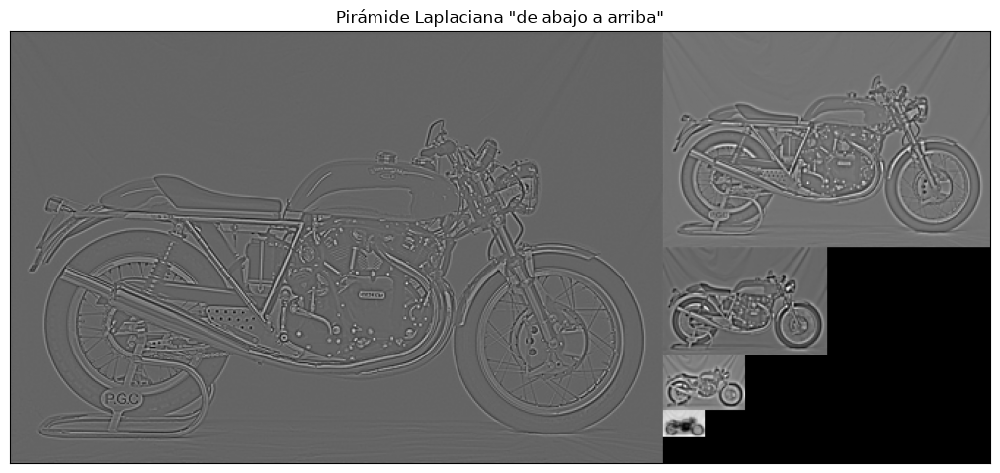

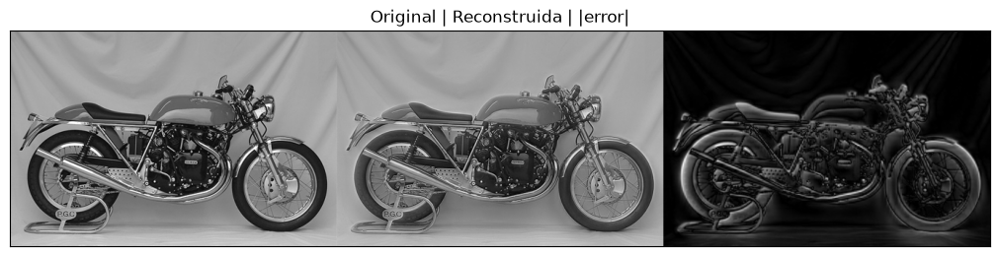

In [18]:
def pyramidLapBottomUp(im, sizeMask=7, nlevel=4):
  mask = gaussianMask1D(sizeMask=sizeMask)
  G, vimL = im.astype(np.float64), []
  for _ in range(nlevel):
    H = cv2.sepFilter2D(G, cv2.CV_64F, mask, mask)      # H(G_i)
    vimL.append(G - H)                                  # L_i = G_i - H(G_i)
    G = H[::2, ::2]                                     # G_{i+1} = H(G_i) submuestreada
  return vimL + [G]

pyrBU = pyramidLapBottomUp(im)
for n in ['LINEAR', 'CUBIC', 'pyrUp']:
  print(f'Reconstrucción con {n:6s} -> Error per pixel {rmse(im, reconstructLap(pyrBU, metodos[n])):.3f}')

recons_bu = reconstructLap(pyrBU, cv2.INTER_LINEAR)
displayPyramid([rangeDisplay01(l) for l in pyrBU], 'Pirámide Laplaciana "de abajo a arriba"')
displayMI_ES([im / 255, np.clip(recons_bu, 0, 255) / 255, rangeDisplay01(np.abs(im - recons_bu))], 'Original | Reconstruida | |error|', 2)

#### Respuesta (2D.3)

**No permite reconstruir:** el error es $14.222$ con bilineal, $12.973$ con bicúbica y $11.659$ con `pyrUp` (salida); con ninguna interpolación llega a 0. Lo que se pierde al submuestrear $H(G_i)$ no está guardado en ningún nivel.

**¿Es un proceso válido?** Como descomposición en detalles multiescala, sí: cada $L_i=(\delta-H)*G_i$ es un paso alto y la pirámide se parece mucho a la estándar. Como pirámide Laplaciana (Burt y Adelson), no: lo que la define es que $L_i$ sea exactamente el error de predicción $G_i-\operatorname{expand}(G_{i+1})$, que es lo que permite invertirla sin pérdidas.

# <font color='blue'>**Ejercicio 3: Imágenes Híbridas** (1.25 puntos)

<font color='blue'>Este ejercicio se basa en el siguiente trabajo: $\textit{Oliva, A., Torralba, A., & Schyns, P. G. (2006). Hybrid images. ACM Transactions on Graphics (TOG), 25(3), 527-532}$ (https://stanford.edu/class/ee367/reading/OlivaTorralb_Hybrid_Siggraph06.pdf).

<font color='blue'>Vamos a profundizar un poco en cómo el sistema visual humano extrae información sobre un objeto en función de la distancia. Para ello, construimos una imagen híbrida a partir de dos imágenes de objetos diferentes. Mezclando adecuadamente parte de las altas frecuencias de una imagen con parte de las bajas frecuencias de la otra, obtenemos una imagen híbrida que muestra diferentes percepciones con la distancia.

<font color='blue'>El sigma empleado para filtrar ambas imágenes (tanto la de alta como la de bajas frecuencias) es el aspecto clave para seleccionar el rango de frecuencias altas y bajas de cada imagen. Cuanto mayor sea el valor sigma, mayor será la eliminación de altas frecuencias de la imagen. Se recomienda elegir este valor por separado para cada una de las imágenes y, de hecho, es deseable tener distintos valores para distintos pares de imágenes.

<font color='blue'>Aspectos de importancia en relación a este ejercicio:

1. Como mínimo, se deben generar las imágenes híbridas correspondientes a  `'cat.bmp'+'dog.bmp'`, `'submarine.bmp'+'fish.bmp'` y `'marilyn.bmp'+'einstein.bmp'` (todas en escala de grises). Y también el alumnado debe escoger, como mínimo, otro par de imágenes de su elección a hibridar en color, fuera de las incluidas en la carpeta compartida en Drive (https://drive.google.com/drive/folders/1UtvY8q6w1Cz9a9T9zxIqSweoRLgNwoW-). Es decir, como mínimo, debe haber $4$ pares de imágenes híbridas como parte de la respuesta a este ejercicio. Se debe emplear una pirámide Gaussiana con $6$ niveles para mostrar el efecto obtenido.

<font color='blue'>**Nota:** de cara a emplear imágenes que no estén en el repositorio compartido, se recomienda que el alumnado emplee un código como el que se muestra a continuación, y que permite descargar sobre la marcha imágenes a partir de una URL dada. En el caso del par de imágenes seleccionado por el alumnado, ambas imágenes deberán tener tamaños compatibles y estar razonablemente alineadas, especialmente en las estructuras que se pretende superponer.






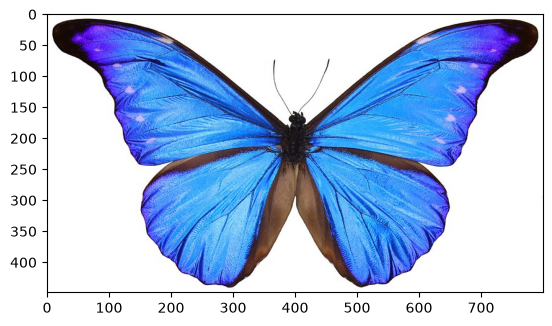

In [19]:
import requests
def downloadImage(url):
    response = requests.get(url)
    img_array = np.frombuffer(response.content, np.uint8)
    img = cv2.imdecode(img_array, cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = img.astype(np.float64)/255
    return img
try:
    smiley_im = downloadImage("https://images.rawpixel.com/image_800/cHJpdmF0ZS9sci9pbWFnZXMvd2Vic2l0ZS8yMDIyLTA1L2ZsMTI5Mjk0MTAxNjUtaW1hZ2Uta3liZW9jNjEuanBn.jpg")
    plt.imshow(smiley_im)
except:
    print("Couldn't download the image from the given URL")

<font color='blue'>2. No es necesario seguir al pie de la letra el artículo de referencia y operar en el dominio de la frecuencia (Fourier). Basta con operar en el dominio del espacio, como hemos hecho en todos los demás apartados de esta práctica. No obstante, sí se debe emplear/buscar algún criterio objetivable/cuantificable a la hora de escoger qué imagen se empleará para las altas frecuencias y cuál para las bajas frecuencias. No basta con escogerla "a ojo" y, al contrario, se debe definir alguna métrica que permita realizar la selección.

<font color='blue'>3. En relación con el punto anterior, se debe explicar con claridad el proceso seguido para filtrar la imagen de altas frecuencias y la de bajas frecuencias, incluyendo la elección de los sigmas finalmente utilizados. La realización de una experimentación preliminar, por medio de prueba y error, es perfectamente válida, pero hay que explicarla y justificarla de algún modo. No basta con probar una serie de valores arbitrarios y justificarlo, sucintamente, indicando que *"se procedió por medio de prueba y error hasta obtener el sigma final"*.

### Teoría y método (Ejercicio 3)

**Híbrida** (Oliva et al., 2006; `2.3`, d. 37): bajas frecuencias de una imagen $B$ más altas de otra $A$,

$$\mathcal H=G_{\sigma_L}*B+\big(A-G_{\sigma_H}*A\big)$$

calculado en el espacio con `my2DConv`. De cerca vemos los detalles (altas) y de lejos la forma global (bajas) (`Assignment2`, d. 50-51). Alejarse equivale a reducir la imagen, por eso el efecto se evalúa con una pirámide Gaussiana de 6 niveles (`Assignment2`, d. 52).

**Criterio objetivo** (elección propia, que concreta la pauta de `Assignment2`, d. 52, de dar las altas a la imagen con más bordes). En cada nivel $l$ de la pirámide se comparan los bordes (magnitud del gradiente, 1B) de la híbrida con los de cada original mediante la correlación normalizada (NCC):

$$D_l=\operatorname{NCC}(\nabla\mathcal H_l,\nabla A_l)-\operatorname{NCC}(\nabla\mathcal H_l,\nabla B_l)$$

$D_l>0$ significa que a esa distancia se ven los bordes de $A$ (altas), y $D_l<0$, los de $B$ (bajas). Se busca que $A$ domine de cerca y $B$ desde el nivel central de la pirámide (3 de 0-6), así que la puntuación es $\min(D_0,-D_3)$. Se prueban **las dos asignaciones de papeles** y $\sigma_L,\sigma_H\in\{1,2,3,4,5,6,8,10,12\}$, y se elige la mejor combinación.

In [20]:
def hybridImage(imLow, imHigh, sigmaLow, sigmaHigh):
  baja = my2DConv(imLow, sigmaLow, [0,0])                 # paso bajo
  alta = imHigh - my2DConv(imHigh, sigmaHigh, [0,0])      # paso alto = original - suavizada
  return baja, alta, baja + alta

def bordesPiramide(x, nlevel=6):
  # Magnitud del gradiente (1B, sigma = 1) en cada nivel de la pirámide Gaussiana, en gris
  x = x if x.ndim == 2 else x.mean(axis=2)
  return [np.hypot(*gradientIM(p, 1)) for p in pyramidGauss(x, 7, nlevel)]

def ncc(a, b):
  return np.corrcoef(a.ravel(), b.ravel())[0, 1]

def showHybrid(imA, imB, nameA, nameB, sigmas=(1, 2, 3, 4, 5, 6, 8, 10, 12)):
  bA, bB = bordesPiramide(imA), bordesPiramide(imB)
  res = []                          # (puntuación, altas, bajas, sigmaLow, sigmaHigh, perfil D)
  for (nh, hi, bh), (nl, lo, bl) in [((nameA, imA, bA), (nameB, imB, bB)), ((nameB, imB, bB), (nameA, imA, bA))]:
    for sL in sigmas:
      for sH in sigmas:
        bH = bordesPiramide(hybridImage(lo, hi, sL, sH)[2])
        D = np.array([ncc(h, a) - ncc(h, b) for h, a, b in zip(bH, bh, bl)])
        res.append((min(D[0], -D[3]), nh, nl, sL, sH, D))
  score, nh, nl, sL, sH, D = max(res, key=lambda t: t[0])
  otra = max((t for t in res if t[1] != nh), key=lambda t: t[0])
  print(f'ALTAS = {nh}, BAJAS = {nl}, sigmaLow = {sL}, sigmaHigh = {sH}, puntuación = {score:.3f}')
  print('Perfil D_l (niveles 0..6):', np.round(D, 2))
  print(f'Mejor con los papeles cambiados (ALTAS = {otra[1]}): sigmaLow = {otra[3]}, sigmaHigh = {otra[4]}, puntuación = {otra[0]:.3f}')

  hi, lo = (imA, imB) if nh == nameA else (imB, imA)
  baja, alta, hyb = hybridImage(lo, hi, sL, sH)
  vmax = 1.0 if hyb.ndim == 3 else 255.0                  # color en [0,1], gris en [0,255]
  displayMI_ES([np.clip(baja, 0, vmax) / vmax, rangeDisplay01(alta), np.clip(hyb, 0, vmax) / vmax], f'Bajas: {nl} | Altas: {nh} | Híbrida', 2)
  displayPyramid([np.clip(p, 0, vmax) / vmax for p in pyramidGauss(hyb, 7, 6)], 'Pirámide Gaussiana de la híbrida (6 niveles)')
  return dict(par=f'{nh} / {nl} (sL={sL}, sH={sH})', D=D)

#### Par 1: gato y perro

ALTAS = gato, BAJAS = perro, sigmaLow = 6, sigmaHigh = 3, puntuación = 0.629
Perfil D_l (niveles 0..6): [ 0.67 -0.05 -0.54 -0.63 -0.68 -0.7  -0.55]
Mejor con los papeles cambiados (ALTAS = perro): sigmaLow = 6, sigmaHigh = 3, puntuación = 0.626


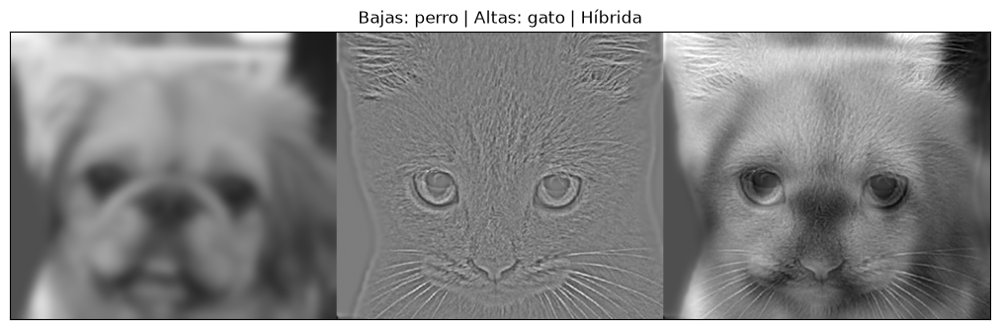

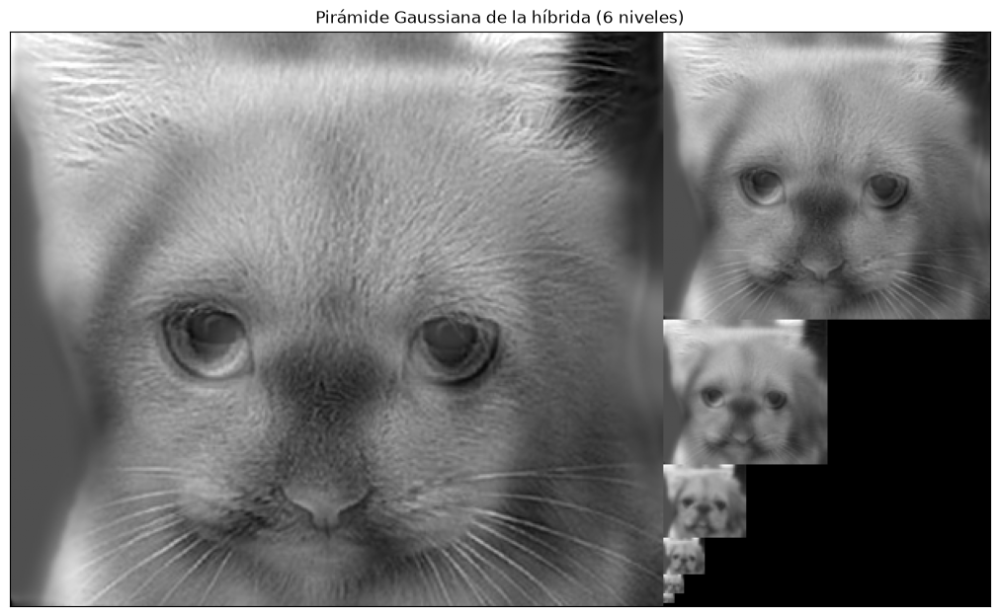

In [21]:
gato  = readIm(get_image('cat.bmp'), 0)
perro = readIm(get_image('dog.bmp'), 0)
res_gp = showHybrid(gato, perro, 'gato', 'perro')

**Análisis.** Altas: **gato** ($\sigma_H=3$); bajas: **perro** ($\sigma_L=6$); puntuación $0.629$ (salida). $D_0=0.67>0$ y desde el nivel 2 $D_l<0$: de cerca se ven el pelo y los bigotes del gato, y de lejos la cara chata del perro. Con los papeles cambiados se obtiene $0.626$ (salida): casi un empate, porque son dos caras de animal con pelo y la misma pose. De cerca aún se intuyen las orejas oscuras del perro, que son bajas frecuencias de mucho contraste.

#### Par 2: submarino y pez

ALTAS = pez, BAJAS = submarino, sigmaLow = 4, sigmaHigh = 2, puntuación = 0.521
Perfil D_l (niveles 0..6): [ 0.57  0.03 -0.47 -0.52 -0.67 -0.65 -0.34]
Mejor con los papeles cambiados (ALTAS = submarino): sigmaLow = 8, sigmaHigh = 5, puntuación = 0.481


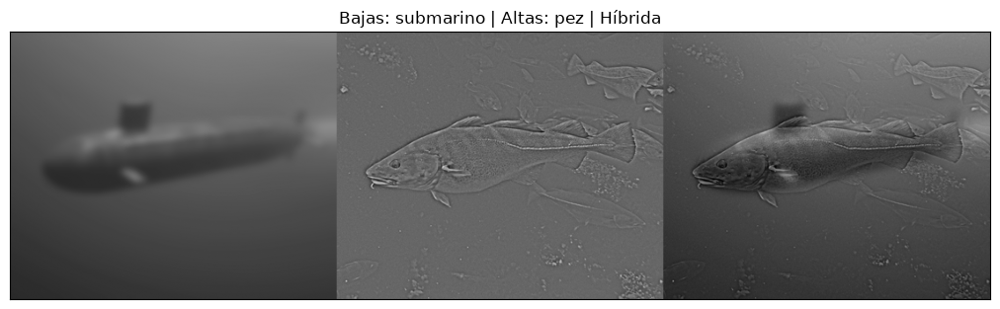

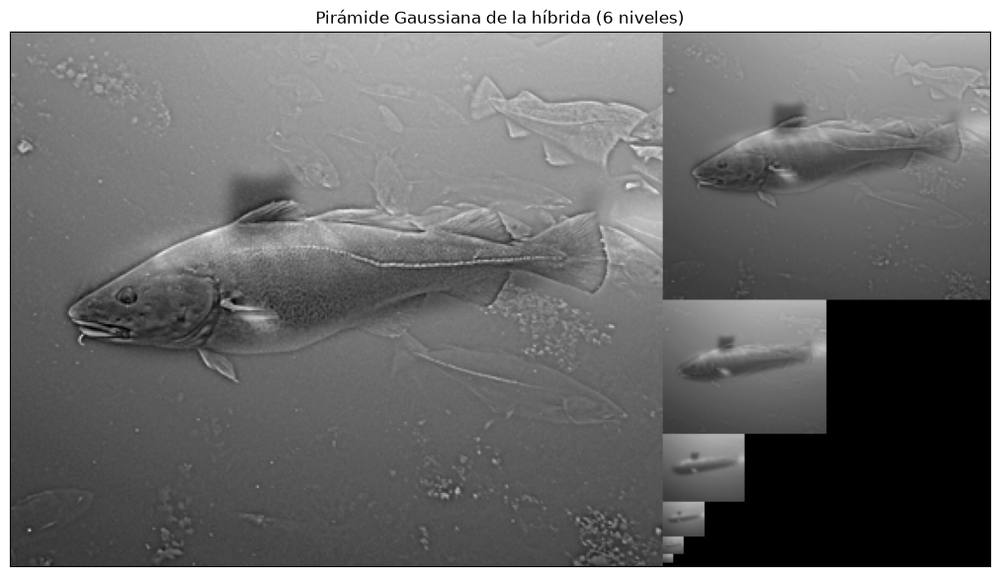

In [22]:
submarino = readIm(get_image('submarine.bmp'), 0)
pez       = readIm(get_image('fish.bmp'), 0)
res_sp = showHybrid(submarino, pez, 'submarino', 'pez')

**Análisis.** Altas: **pez** ($\sigma_H=2$); bajas: **submarino** ($\sigma_L=4$); puntuación $0.521$, frente a $0.481$ con los papeles cambiados (salida). Tiene sentido: el submarino es una silueta lisa sobre agua uniforme y el pez tiene escamas, aletas y un fondo de peces. Es la puntuación más baja de los cuatro pares porque la alineación es peor: la vela del submarino sobresale por encima del pez y se ve como un rectángulo oscuro a cualquier distancia.

#### Par 3: Marilyn y Einstein

ALTAS = Einstein, BAJAS = Marilyn, sigmaLow = 8, sigmaHigh = 3, puntuación = 0.777
Perfil D_l (niveles 0..6): [ 0.81  0.45 -0.37 -0.78 -0.84 -0.61 -0.23]
Mejor con los papeles cambiados (ALTAS = Marilyn): sigmaLow = 6, sigmaHigh = 5, puntuación = 0.762


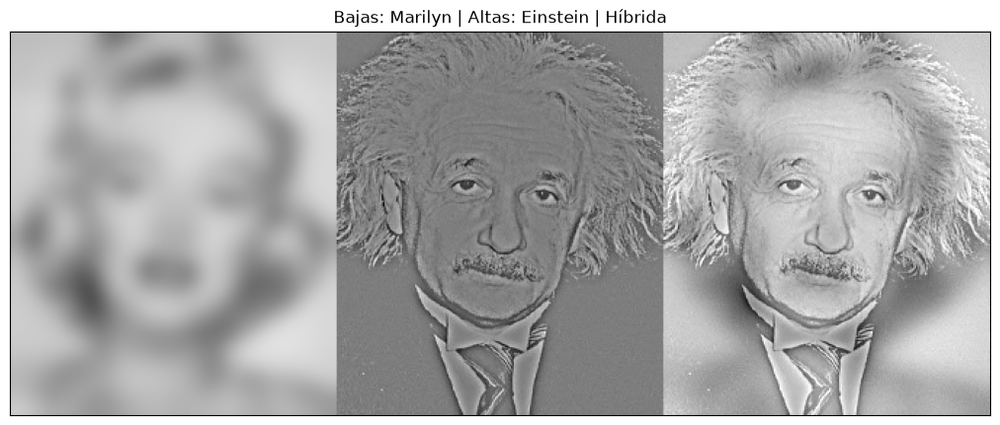

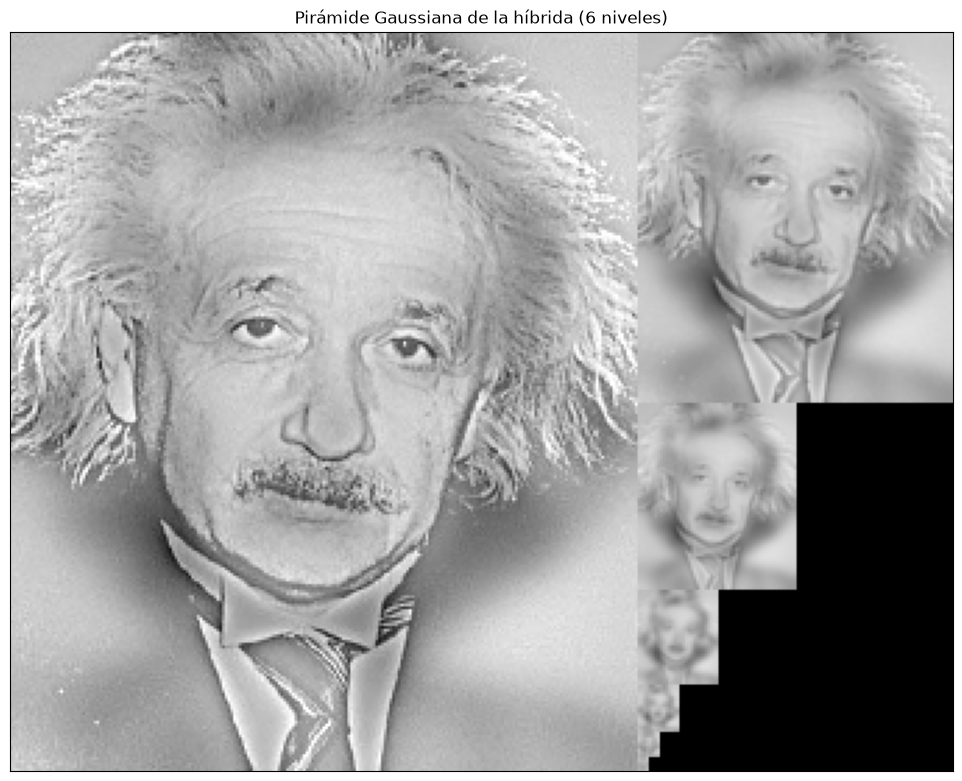

In [23]:
marilyn  = readIm(get_image('marilyn.bmp'), 0)
einstein = readIm(get_image('einstein.bmp'), 0)
res_me = showHybrid(marilyn, einstein, 'Marilyn', 'Einstein')

**Análisis.** Altas: **Einstein** ($\sigma_H=3$); bajas: **Marilyn** ($\sigma_L=8$); puntuación $0.777$, frente a $0.762$ con los papeles cambiados (salida). Es la misma asignación que la híbrida original de Oliva et al. El retrato de Einstein tiene mucha textura fina (pelo, arrugas, bigote) que sobrevive al paso alto; el de Marilyn se define por grandes zonas de contraste (peinado, labios), que siguen siendo reconocibles al reducir la imagen. En el nivel 3 ya se ve claramente a Marilyn.

#### Par 4 (propio, en color): gato y mandril

Escala = 1.0226 | giro = -9.20 grados
Tamaño tras el recorte: (208, 433, 3)


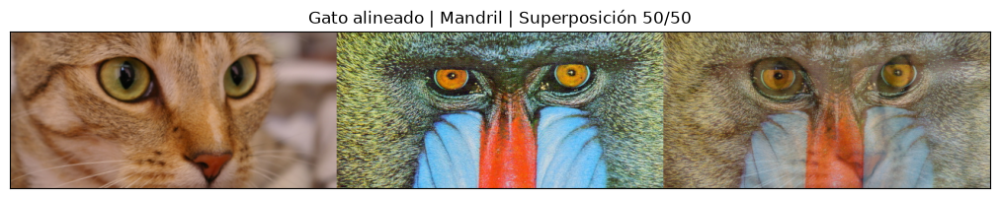

ALTAS = mandril, BAJAS = gato, sigmaLow = 6, sigmaHigh = 4, puntuación = 0.899
Perfil D_l (niveles 0..6): [ 0.91  0.43 -0.49 -0.9  -0.8  -0.61 -0.72]
Mejor con los papeles cambiados (ALTAS = gato): sigmaLow = 8, sigmaHigh = 5, puntuación = 0.858


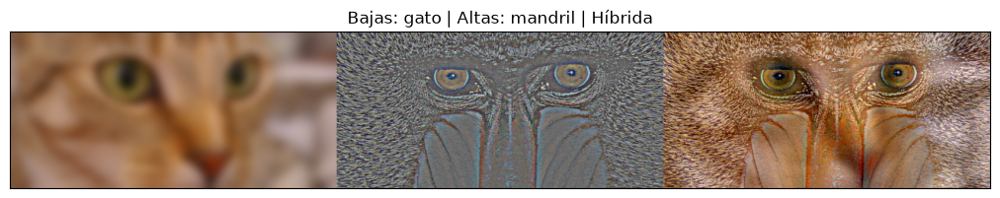

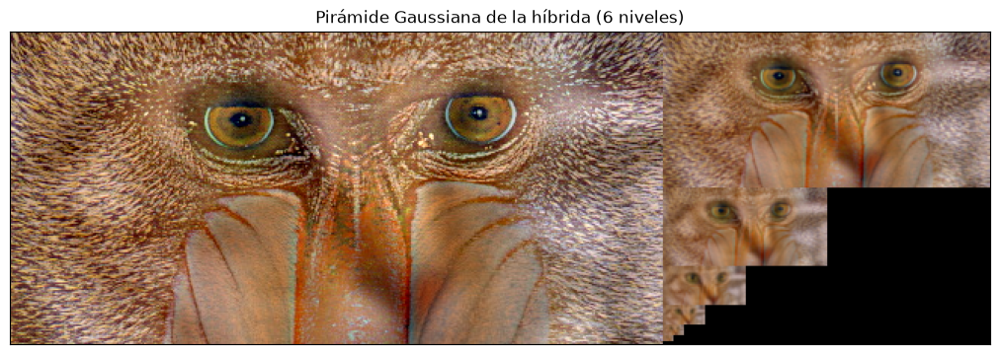

In [24]:
# Par propio en color: gato "Chelsea" (scikit-image) y mandril (OpenCV), con URLs fijadas a una versión
gato_c    = downloadImage('https://raw.githubusercontent.com/scikit-image/scikit-image/v0.22.0/skimage/data/chelsea.png')
mandril_c = downloadImage('https://raw.githubusercontent.com/opencv/opencv/4.10.0/samples/data/baboon.jpg')

# Alineación por los ojos (x, y), marcados a mano sobre una rejilla de coordenadas. Se añade un tercer
# punto girando 90º el vector entre los ojos para que la afín sea una semejanza (giro + escala + traslación)
tres = lambda p: np.float32([p[0], p[1], (p[0][0] - (p[1][1] - p[0][1]), p[0][1] + (p[1][0] - p[0][0]))])
M = cv2.getAffineTransform(tres([(172, 113), (320, 135)]), tres([(177, 60), (330, 58)]))
print(f'Escala = {np.hypot(M[0,0], M[1,0]):.4f} | giro = {np.degrees(np.arctan2(M[1,0], M[0,0])):.2f} grados')
H, W = mandril_c.shape[:2]
gato_w = cv2.warpAffine(gato_c, M, (W, H))
valido = cv2.warpAffine(np.ones(gato_c.shape[:2]), M, (W, H)) > 0.999

# Recorte al mayor rectángulo sin píxeles vacíos: se quita cada vez el borde con más píxeles inválidos
r0, r1, c0, c1 = 0, H, 0, W
while not valido[r0:r1, c0:c1].all():
  s = ~valido[r0:r1, c0:c1]
  k = np.argmax([s[0].sum(), s[-1].sum(), s[:, 0].sum(), s[:, -1].sum()])
  r0, r1, c0, c1 = [(r0+1, r1, c0, c1), (r0, r1-1, c0, c1), (r0, r1, c0+1, c1), (r0, r1, c0, c1-1)][k]
gato_a, mandril_a = gato_w[r0:r1, c0:c1], mandril_c[r0:r1, c0:c1]
print('Tamaño tras el recorte:', gato_a.shape)
displayMI_ES([gato_a, mandril_a, (gato_a + mandril_a) / 2], 'Gato alineado | Mandril | Superposición 50/50', 2)

res_gm = showHybrid(gato_a, mandril_a, 'gato', 'mandril')

**Análisis.** La semejanza tiene escala $1.0226$ y giro $-9.20°$ (salida): las caras ya tenían tamaño parecido y lo principal es enderezar la cabeza del gato. La superposición 50/50 muestra los ojos coincidentes. Altas: **mandril** ($\sigma_H=4$); bajas: **gato** ($\sigma_L=6$); puntuación $0.899$, la mejor de los cuatro pares, frente a $0.858$ con los papeles cambiados (salida): el pelaje del mandril es textura muy densa. Los azules y rojos del hocico del mandril **no** aparecen en la híbrida: son regiones de color uniforme, es decir, bajas frecuencias, y el paso alto las elimina; el color lo aporta el gato.

#### Resumen

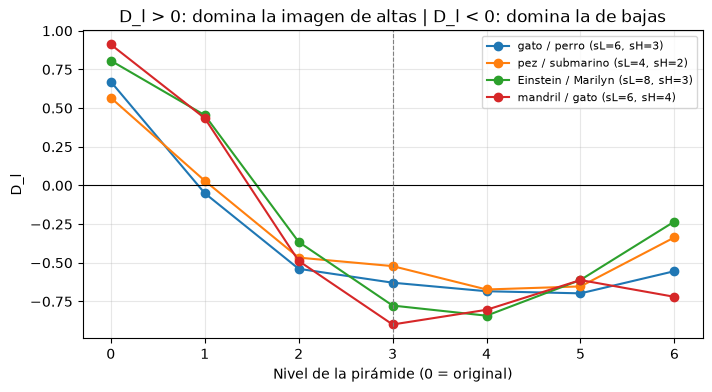

In [25]:
plt.figure(figsize=(8, 4))
for res in [res_gp, res_sp, res_me, res_gm]:
  plt.plot(res['D'], 'o-', label=res['par'])
plt.axhline(0, color='k', lw=0.8); plt.axvline(3, color='gray', ls='--', lw=0.8)
plt.xlabel('Nivel de la pirámide (0 = original)'); plt.ylabel('D_l')
plt.title('D_l > 0: domina la imagen de altas | D_l < 0: domina la de bajas')
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

### Análisis global (Ejercicio 3)

- **El efecto se consigue en los cuatro pares:** $D_0>0$ y $D_l<0$ desde el nivel 2 (gráfica). Ninguna imagen domina en todos los niveles, que es la condición de éxito de `Assignment2` (d. 52).
- **Los $\sigma$ dependen del par** ($\sigma_L$ de 4 a 8, $\sigma_H$ de 2 a 4), como anticipaba el enunciado, y siempre $\sigma_L>\sigma_H$. Como la Gaussiana de $\sigma$ en el espacio tiene anchura $1/(2\pi\sigma)$ en frecuencia (`2.3`, d. 63; cálculo propio), queda una franja intermedia que ninguna imagen aporta con fuerza, lo que reduce la interferencia entre ambas.
- **Limitación.** $D_l$ aproxima la percepción con correlaciones de bordes, y elegir el nivel 3 y el rango de $\sigma$ son decisiones de diseño. Aun así, la métrica reproduce la asignación de Oliva et al. en Marilyn/Einstein.

# <font color='blue'>**Ejercicio 4: Pyramid Blending** (1.25 puntos)

<font color='blue'>En este ejercicio se deberá construir una imagen fusionada a partir de un par de imágenes reales, correspondiente a las imágenes de la manzana y la naranja. Se debe crear la imagen fusionada de la manzana (`apple.jpg`; parte izquierda de la imagen fusionada final) y la naranja (`orange.jpg`; parte derecha de la imagen fusionada final).

<font color='blue'>No se podrán utilizar directamente las funciones `cv2.pyrDown()` ni `cv2.pyrUp()`. La construcción de las pirámides deberá realizarse haciendo uso de las operaciones de suavizado, submuestreo e interpolación implementadas previamente en la práctica.

<font color='blue'>Se deberá:

1. <font color='blue'>Explicar detalladamente el procedimiento seguido para obtener la imagen fusionada, incluyendo la construcción de las pirámides gaussianas y laplacianas, la mezcla de los distintos niveles y la posterior reconstrucción de la imagen final.

2. <font color='blue'>Comparar  el resultado obtenido mediante pyramid blending con dos alternativas más sencillas:
   - <font color='blue'>una combinación directa, sin blending, formada tomando los píxeles de la mitad izquierda de una imagen y los de la mitad derecha de la otra;
   - una combinación a una única escala, empleando una sola máscara binaria suavizada mediante un filtro gaussiano (con $\sigma$ = $2$, $5$ y $15$) para mezclar directamente ambas imágenes a resolución completa.

3. <font color='blue'>Visualizar los principales estados intermedios del proceso. En particular, se deberán mostrar:
   - <font color='blue'>las pirámides gaussianas (de la manzana, la naranja y la máscara binaria) con seis niveles cada una;
   - las pirámides laplacianas correspondientes (de la manzana y la naranja);
   - y la laplaciana fusionada con los distintos niveles resultantes de la mezcla.

4. <font color='blue'>Finalmente, se deberá responder razonadamente a la siguiente cuestión:
> <font color='blue'>¿En qué situaciones resulta ventajoso emplear pyramid blending frente a utilizar una única máscara suavizada? ¿En qué casos podría ser suficiente una mezcla a una sola escala?




### Teoría (Ejercicio 4)

**El problema.** Con una transición estrecha se ve el salto de color (bajas frecuencias); con una ancha, las texturas de las dos frutas se superponen y aparecen "fantasmas" (*ghosting*). Ninguna anchura única sirve para todas las frecuencias (Burt y Adelson, 1983).

**Pyramid blending** (`2.3`, d. 31-32; `Assignment2`, d. 54-55):

1. Pirámides Laplacianas $L_A$ (manzana) y $L_B$ (naranja), con las funciones del Ejercicio 2.
2. Pirámide Gaussiana $G_R$ de la máscara binaria $R$ (1 = manzana). En el nivel $i$ la transición ocupa unos $2^i$ píxeles a resolución original: estrecha para el detalle fino y ancha para el color.
3. Mezcla por niveles: $L_S^{(i)}=G_R^{(i)}L_A^{(i)}+\big(1-G_R^{(i)}\big)L_B^{(i)}$.
4. Reconstrucción de $L_S$ como en el 2C.

Se trabaja en color en $[0,1]$, con 6 niveles (original + 6) y recortando ambas imágenes a su zona central común, sin interpolar. Para comparar con las alternativas del enunciado se usan dos métricas propias: el **salto en la costura** (gradiente horizontal medio junto a la frontera; menor es mejor) y la **conservación del detalle** (NCC de las altas frecuencias con la referencia manzana | naranja cerca de la frontera; cerca de 1 = sin *ghosting*).

Tamaños originales: (239, 238, 3) (240, 240, 3) -> común: (239, 238)


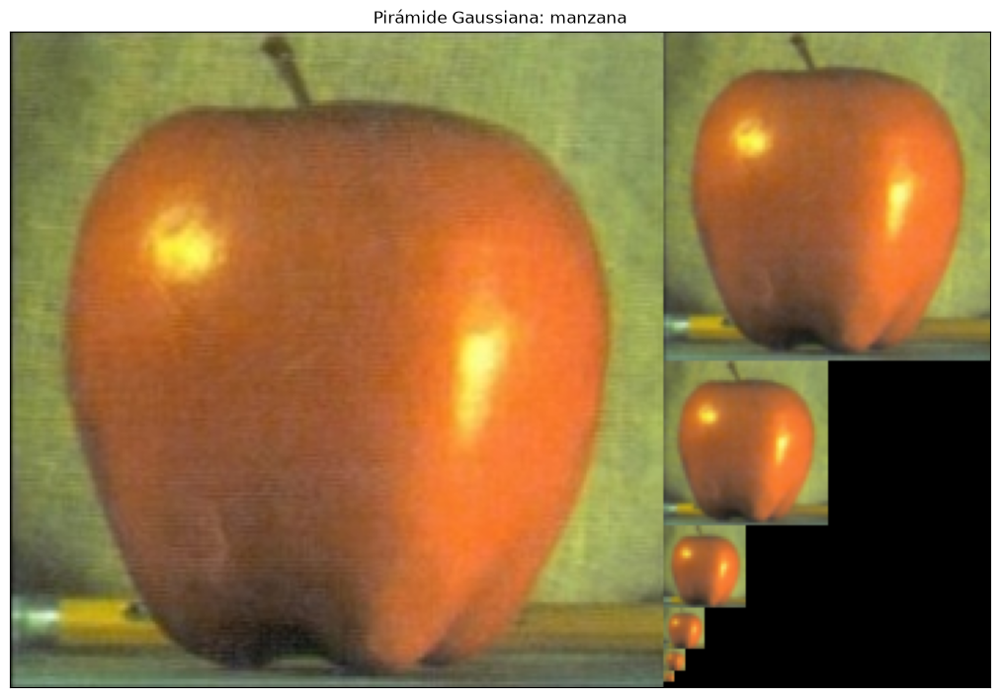

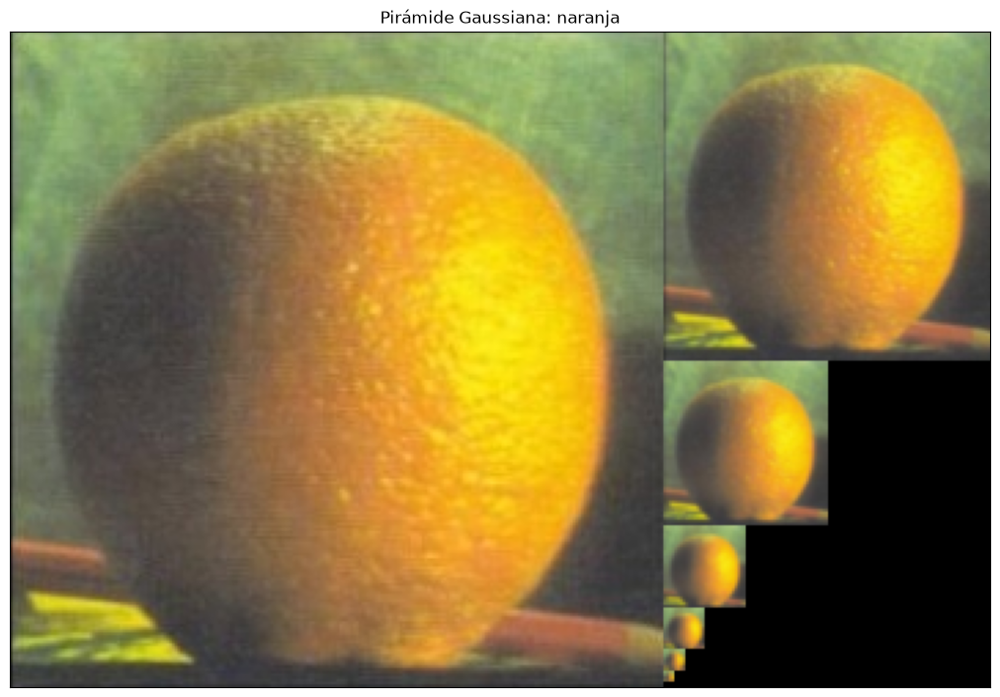

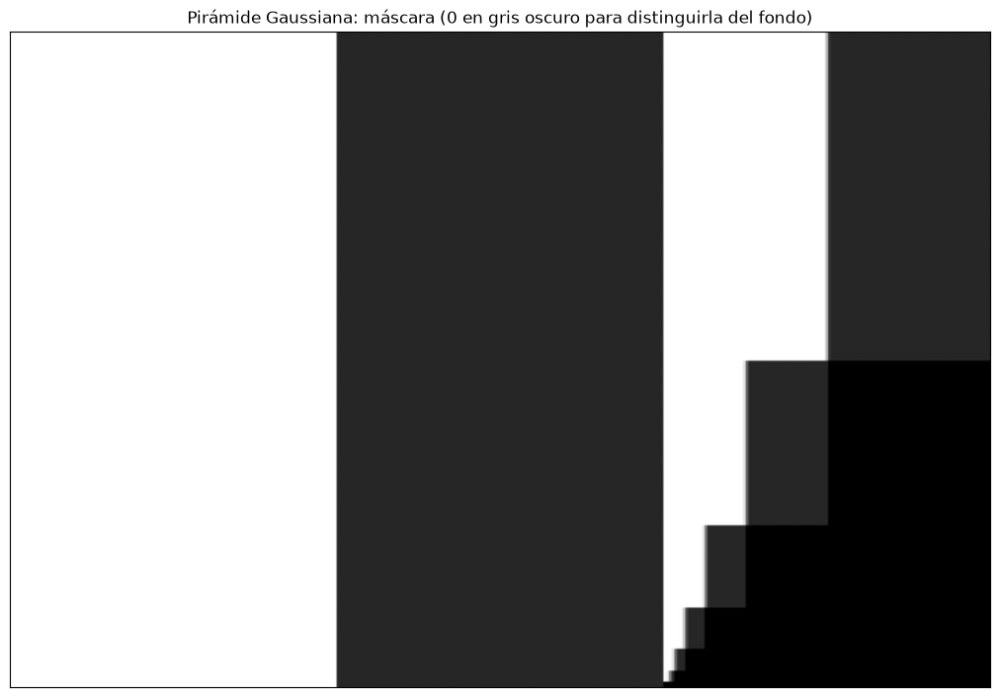

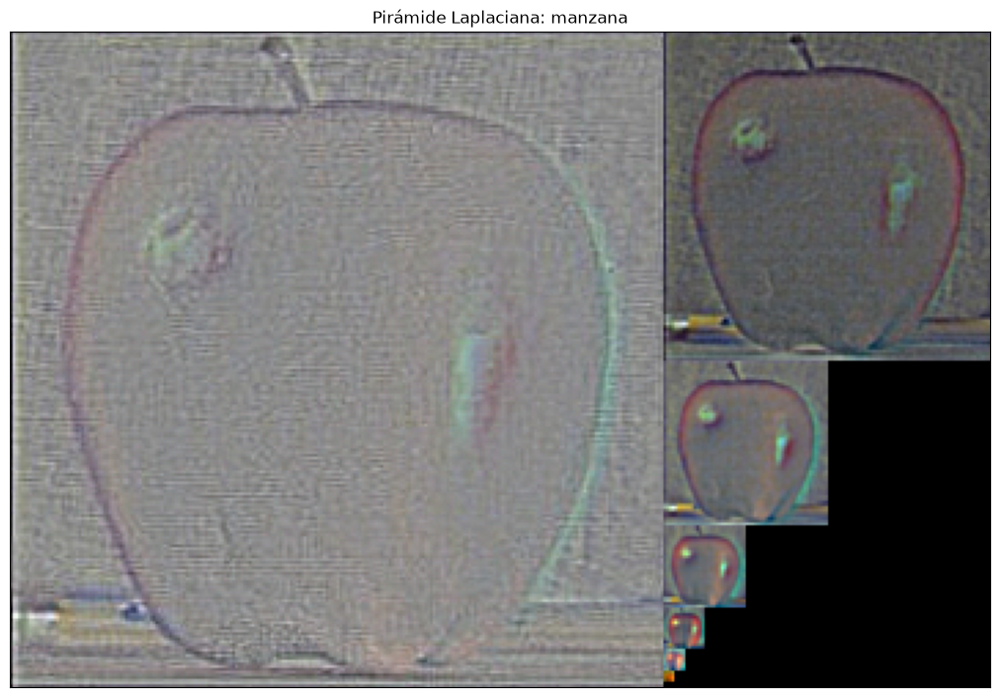

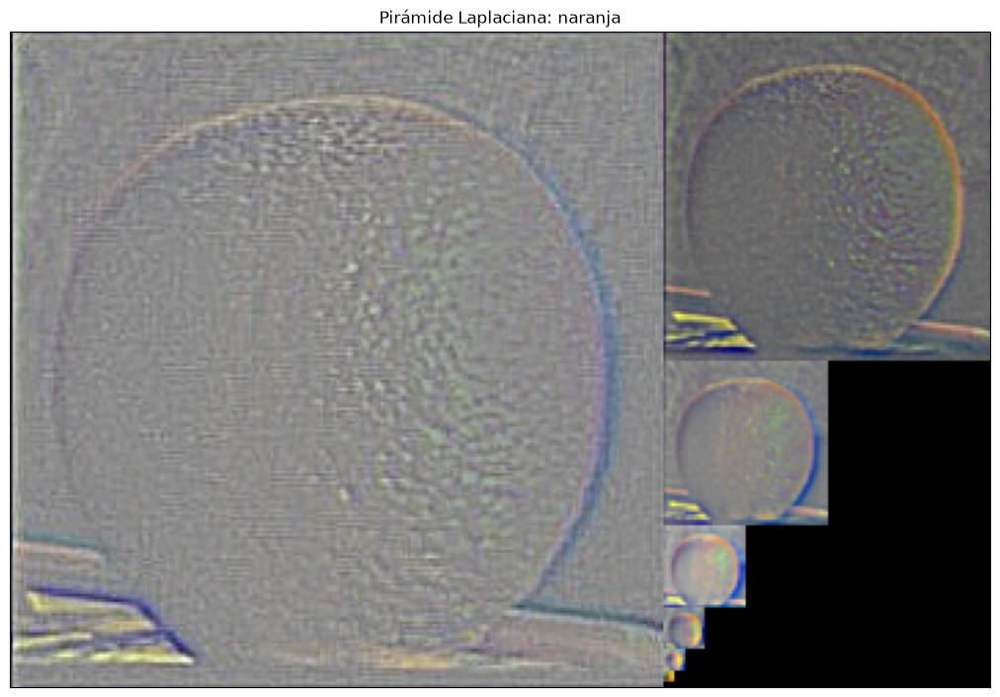

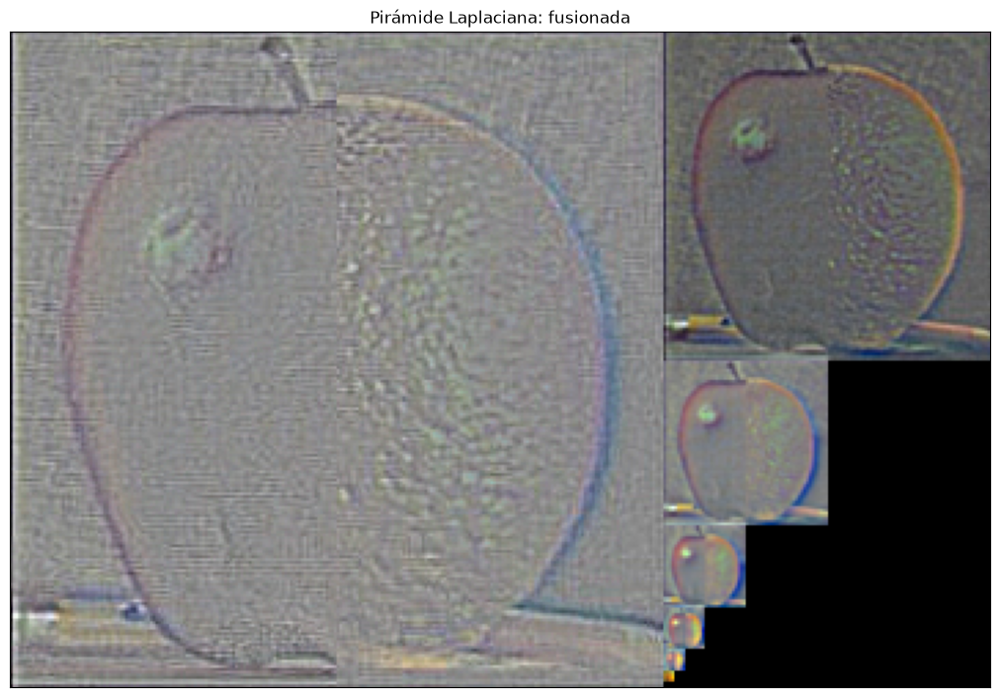

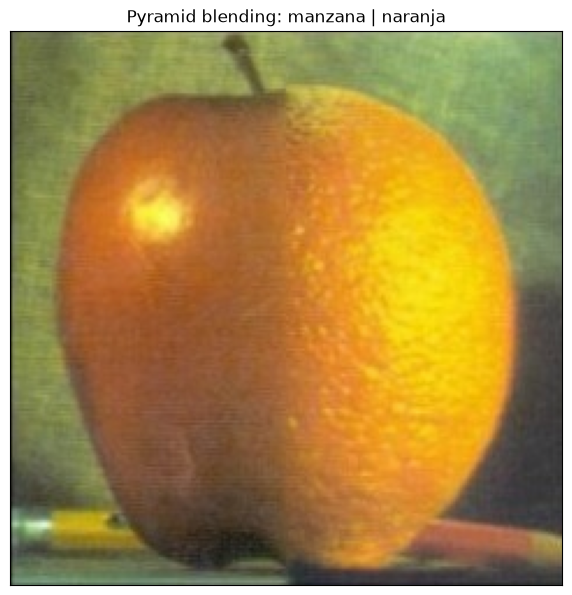

In [26]:
manzana = readIm(get_image('apple.jpg'), 1).astype(np.float64) / 255
naranja = readIm(get_image('orange.jpg'), 1).astype(np.float64) / 255
h, w = min(manzana.shape[0], naranja.shape[0]), min(manzana.shape[1], naranja.shape[1])
def recorteCentral(x):
  y0, x0 = (x.shape[0] - h) // 2, (x.shape[1] - w) // 2
  return x[y0:y0+h, x0:x0+w]
print('Tamaños originales:', manzana.shape, naranja.shape, '-> común:', (h, w))
manzana, naranja = recorteCentral(manzana), recorteCentral(naranja)

R = np.zeros((h, w)); R[:, :w//2] = 1                    # máscara: 1 = manzana (izquierda)
GA, GB, GR = [pyramidGauss(x, 7, 6) for x in (manzana, naranja, R)]
LA, LB = laplacianFromGauss(GA, cv2.INTER_LINEAR), laplacianFromGauss(GB, cv2.INTER_LINEAR)
LS = [m[..., None] * a + (1 - m[..., None]) * b for m, a, b in zip(GR, LA, LB)]   # mezcla nivel a nivel
fusion = np.clip(reconstructLap(LS, cv2.INTER_LINEAR), 0, 1)

displayPyramid(GA, 'Pirámide Gaussiana: manzana')
displayPyramid(GB, 'Pirámide Gaussiana: naranja')
displayPyramid([0.15 + 0.85 * g for g in GR], 'Pirámide Gaussiana: máscara (0 en gris oscuro para distinguirla del fondo)')
for L, t in [(LA, 'manzana'), (LB, 'naranja'), (LS, 'fusionada')]:
  displayPyramid([rangeDisplay01(l) for l in L], f'Pirámide Laplaciana: {t}')
displayIm(fusion, 'Pyramid blending: manzana | naranja', 1.5)

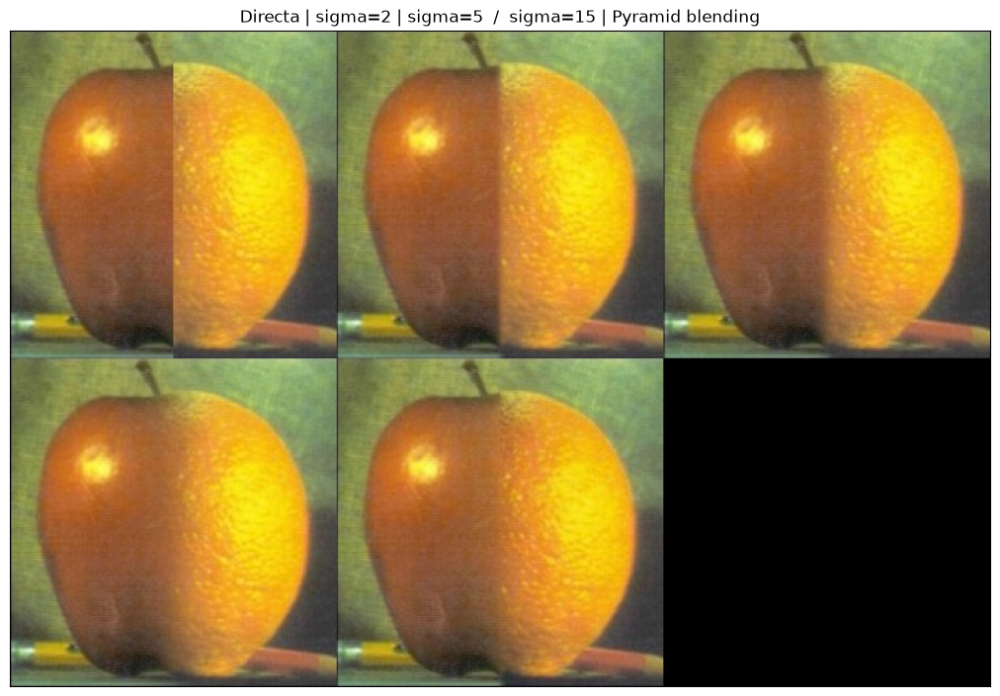

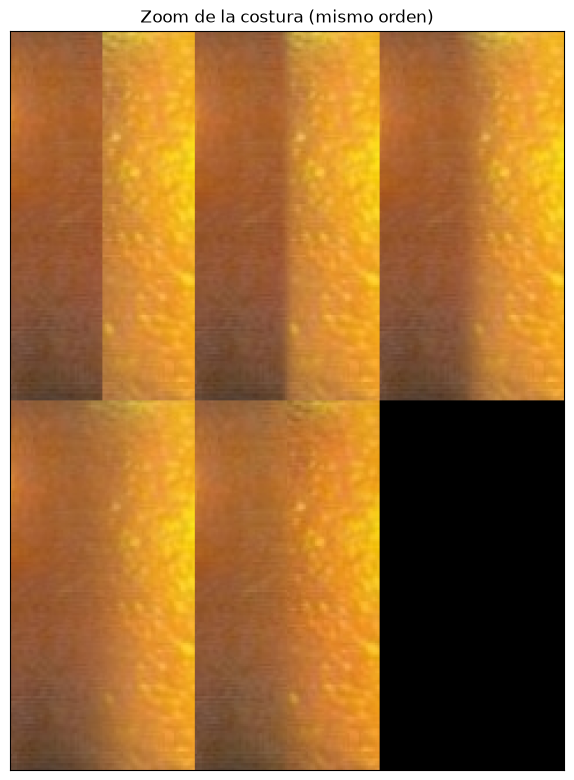

Directa   salto = 0.0478 | detalle = 1.000
sigma=2   salto = 0.0250 | detalle = 0.992
sigma=5   salto = 0.0129 | detalle = 0.982
sigma=15  salto = 0.0087 | detalle = 0.913
Pyramid   salto = 0.0144 | detalle = 0.995
Salto medio en toda la imagen (directa): 0.0116


In [27]:
def unaEscala(s):
  m = my2DConv(R, s, [0,0])[..., None]                   # máscara binaria suavizada
  return np.clip(m * manzana + (1 - m) * naranja, 0, 1)

metodos = {'Directa': np.where(R[..., None] > 0.5, manzana, naranja),
           'sigma=2': unaEscala(2), 'sigma=5': unaEscala(5), 'sigma=15': unaEscala(15), 'Pyramid': fusion}
displayMI_ES(list(metodos.values()), 'Directa | sigma=2 | sigma=5  /  sigma=15 | Pyramid blending', 2)
c = w // 2
displayMI_ES([cv2.resize(x[40:200, c-40:c+40], None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST) for x in metodos.values()],
             'Zoom de la costura (mismo orden)', 2)

# Métricas, en gris: salto medio en las columnas de la costura y NCC de las altas frecuencias con la
# referencia (directa) en una banda de +-10 columnas, sin las 3 centrales, donde la referencia tiene el corte
gris  = lambda x: x.mean(axis=2)
altas = lambda x: gris(x) - my2DConv(gris(x), 2, [0,0])
cols, ref = np.r_[c-10:c-3, c+3:c+10], altas(metodos['Directa'])
for n, x in metodos.items():
  print(f'{n:<9} salto = {np.abs(np.diff(gris(x), axis=1))[:, c-2:c+1].mean():.4f} | detalle = {ncc(altas(x)[:, cols], ref[:, cols]):.3f}')
print('Salto medio en toda la imagen (directa):', round(np.abs(np.diff(gris(metodos["Directa"]), axis=1)).mean(), 4))

### Análisis y respuesta (Ejercicio 4)

**Estados intermedios.** La máscara se va suavizando nivel a nivel; en la cima casi toda es transición. Las Laplacianas separan escalas: en $L_0$ y $L_1$ se ven los poros de la naranja y la manzana casi lisa; en los niveles altos, solo el color y los contornos. La fusionada tiene manzana a la izquierda y naranja a la derecha, con un cambio abrupto en los niveles finos y gradual en los gruesos. En el resultado el color pasa suavemente del rojo al naranja y los poros terminan de forma nítida.

**Comparación** (salida; salto medio en toda la imagen: $0.0116$):

| Método | Salto en la costura | Conservación del detalle |
|---|---|---|
| Directa | $0.0478$ | $1.000$ |
| $\sigma=2$ | $0.0250$ | $0.992$ |
| $\sigma=5$ | $0.0129$ | $0.982$ |
| $\sigma=15$ | $0.0087$ | $0.913$ |
| **Pyramid** | $0.0144$ | $0.995$ |

- **Directa:** el salto es $0.0478/0.0116\approx4.1$ veces el gradiente medio (cálculo propio); el corte se ve claramente. Su detalle es 1 por definición, ya que es la referencia.
- **$\sigma=2$:** reduce el salto a la mitad, pero la costura se sigue viendo.
- **$\sigma=15$:** el salto más bajo, a costa del peor detalle ($0.913$): en el zoom se ve una franja ancha en la que la textura de la naranja se transparenta sobre la manzana (*ghosting*).
- **Pyramid:** un salto cercano al de cualquier zona de la imagen y el mejor detalle de todas las mezclas ($0.995$). Una sola máscara obliga a elegir entre ocultar el color o mantener la textura; la pirámide hace las dos cosas porque cada banda se mezcla con una anchura acorde a su escala.

**¿Cuándo compensa el pyramid blending?** Cuando las imágenes difieren a la vez en bajas frecuencias (color, iluminación) y en texturas cerca de la frontera, como en este caso; en mosaicos y panorámicas, donde hay diferencias de exposición y pequeños desalineamientos que una transición ancha duplicaría (la aplicación original de Burt y Adelson); y cuando la frontera cruza zonas con mucho detalle.

**¿Cuándo basta una sola escala?** Cuando las dos imágenes son muy parecidas junto a la frontera (misma escena, exposición y textura), cuando la frontera pasa por zonas lisas (cielo, fondo uniforme), cuando la imagen tiene una sola escala dominante (basta ajustar $\sigma$ a ella) o cuando el coste importa: un filtrado frente a construir y colapsar tres pirámides.

## Referencias

- P. Mesejo, apuntes de Visión por Computador (UGR): `2.1.ImageFiltering`, `2.2.GaussianFilters_Edges`, `2.3.Pyramids`; diapositivas del enunciado `Assignment2` (P. Mesejo y S. Tabik).
- R. Szeliski, *Computer Vision: Algorithms and Applications*, 2.ª ed., Springer, 2022, §3.2.
- P. J. Burt y E. H. Adelson, "The Laplacian Pyramid as a Compact Image Code", *IEEE Trans. Communications*, 31(4), 1983.
- P. J. Burt y E. H. Adelson, "A multiresolution spline with application to image mosaics", *ACM Trans. Graphics*, 2(4), 1983.
- A. Oliva, A. Torralba y P. G. Schyns, "Hybrid images", *ACM Trans. Graphics*, 25(3), 2006.
- Imágenes externas: *chelsea.png* (scikit-image v0.22.0) y *baboon.jpg* (OpenCV 4.10.0).